# 01 — Descriptive Analysis and Data Quality Gate

## Objective
Audit the complete Digikala comments and products CSV files before modeling. This notebook verifies schema and quality requirements, reports missing/malformed/duplicate/out-of-range records, describes target and text distributions, and documents findings that affect modeling.

## Reproducibility and safety
- All global counts are computed over the complete files using CSV chunking; physical lines are never counted as records.
- Examples and text-class comparisons use a deterministic bounded sample where noted.
- Raw files are read-only. This notebook does **not** delete, overwrite, or silently correct source records.
- `rate` is read as text for the quality gate. Parsing is assessed explicitly; invalid values are counted before any numeric conversion.
- Duplicate `id` policy: report all repeated IDs and their rows; do not automatically drop them during this audit. A later cleaning step must document the chosen policy.


In [45]:
from pathlib import Path
from collections import Counter, defaultdict
import json
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_SEED = 42
CHUNK_SIZE = 100_000
DATA_DIR = Path("../data")
COMMENTS_PATH = DATA_DIR / "digikala-comments.csv"
PRODUCTS_PATH = DATA_DIR / "digikala-products.csv"

if not COMMENTS_PATH.exists():
    raise FileNotFoundError(f"Comments file not found: {COMMENTS_PATH.resolve()}")
if not PRODUCTS_PATH.exists():
    raise FileNotFoundError(f"Products file not found: {PRODUCTS_PATH.resolve()}")

print(f"Working directory: {Path.cwd()}")
for path in [COMMENTS_PATH, PRODUCTS_PATH]:
    print(f"{path.name}: {path.stat().st_size / (1024**2):,.2f} MiB")


Working directory: d:\AI Bootcamp_M Sharif\digikala_reviews_project\notebooks
digikala-comments.csv: 1,219.30 MiB
digikala-products.csv: 246.75 MiB


### 0. Observing Dataset

In [46]:
products = pd.read_csv(PRODUCTS_PATH, nrows=10)
display(products)

comments = pd.read_csv(COMMENTS_PATH, nrows=10)
display(comments)

,id,title_fa,Rate,Rate_cnt,Category1,Category2,Brand,Price,Seller,Is_Fake,min_price_last_month,sub_category
0,7096438,آبسلانگ مدل s5 بسته 250 عددی,90,4,آبسلانگ,NaN,متفرقه,634800,سلامت ساز راد,False,0,beauty
1,2845119,آبسلانگ مدل M-1 بسته 400 عددی,84,217,آبسلانگ,NaN,متفرقه,818800,مهر افزون,False,0,beauty
2,6117745,آبسلانگ مدل m50 مجموعه 500 عددی,88,14,آبسلانگ,NaN,متفرقه,920000,یانگوم,False,0,beauty
3,1912926,استند ابسلانگ مدل S01,78,25,آبسلانگ,NaN,متفرقه,1100000,بهراد طب بیدار,False,0,beauty
4,6335462,آبسلانگ نوری تسلامد مدل All-in-One,84,25,آبسلانگ,NaN,تسلا مد,1530000,دیجی‌کالا,False,0,beauty
5,6335562,سری آبسلانگ تسلامد مدل All-In-One بسته 100 عددی,80,6,آبسلانگ,NaN,تسلا مد,1521000,دیجی‌کالا,False,0,beauty
6,7096725,آبسلانگ مدل s20 بسته 1000 عددی,84,6,آبسلانگ,NaN,متفرقه,1889500,سلامت ساز راد,False,0,beauty
7,7096768,آبسلانگ مدل s10 بسته 500 عددی,100,2,آبسلانگ,NaN,متفرقه,1872000,سلامت ساز راد,False,0,beauty
8,6005981,استند آبسلانگ گلدن بیوتی مدل 01,84,5,آبسلانگ,NaN,متفرقه,1940000,گلد بیوتی سنتر,False,0,beauty
9,4077287,آبسلانگ پل ایده آل پارس مدل TD بسته 150 عددی,90,15,آبسلانگ,NaN,پل ایده آل پارس,2150000,یاساطب,False,0,beauty


,id,title,body,created_at,rate,recommendation_status,is_buyer,product_id,advantages,disadvantages,likes,dislikes,seller_title,seller_code,true_to_size_rate
0,53672599,پیشنهاد نمیشود,به درد نمیخوره,23 شهریور 1402,1.0,not_recommended,True,252058,NaN,NaN,0,0,دیجی‌کالا,5A52N,NaN
1,9897229,بسته بندی بد,می‌تونست به عنوان یه کالای فرهنگی بهتر بسته بندی بشه,16 تیر 1399,0.0,recommended,True,252058,['تجربه جالبی بود برام '],['بسته بندی جالبی نداشت'],1,0,دیجی‌کالا,5A52N,NaN
2,38074516,برس ریمل,بسته بندیش خوب بود\r\n کاربرد و کیفیتشم خیلی خوبه من برای روغن زدم به مژه و لیفت ابرو خریدم,26 مرداد 1401,0.0,recommended,True,3331597,NaN,NaN,0,0,آرالیا بیوتی,ADM47,NaN
3,18628562,خوبه و خوشرنگ,به نظرم خوبه فقط یکم ظریفه. از رنگش خوشم اومد من برای صابون ابرو استفاده میکنم راضی ام,28 اسفند 1399,0.0,recommended,True,3331329,NaN,NaN,0,0,اینجاست آ,9ZMCZ,NaN
4,53301258,برس رنگ مو,معمولیه اگه واسه خونه رنگ کردن شخصی میخواین اوکیه ولی اگه واسه کار دکلره میخواین نه زیاد ولی خوبه,12 شهریور 1402,3.0,recommended,True,3255700,NaN,NaN,0,0,گالری آرایشی به سیما,CDWHA,NaN
5,53266157,خوبه,قبلا هم استفاده کردم اگه بلد باشین کار کردن باهاش رو \r\nبرای ی پاکسازی پوست سطحی توی خونه عالیه,11 شهریور 1402,5.0,recommended,True,3305270,NaN,NaN,0,0,یانگوم,ERKSP,NaN
6,46206235,بدک نیست,خوبه,8 اسفند 1401,2.0,NaN,True,3480048,NaN,NaN,0,0,بازرگانی سوشیان,CKWY4,NaN
7,40597171,پد شستشوی براش,خیلی به کارتون میاد قیمتشم مناسبه,24 مهر 1401,5.0,recommended,True,3480048,"['جنسش خوبه\r', 'خوش رنگه\r', 'کاربردیه\r', 'قیمت مناسب']",['نداره '],1,0,بازرگانی سوشیان,CKWY4,NaN
8,46198656,لنز ناخون,دقیقا مطابق عکس بود,7 اسفند 1401,5.0,recommended,True,7626372,NaN,NaN,0,0,هستی نیل,E2C2D,NaN
9,46901811,خوب,برا حالت دادن با اسپری یا پودر عالیه,20 اسفند 1401,5.0,recommended,True,821812,NaN,NaN,0,0,پنی شاپ,CN6G3,NaN


## 1. Schema and quality gate — comments

The required modeling/audit columns are `id`, `body`, `rate`, `recommendation_status`, and `product_id`. The notebook also checks the additional columns named in the project definition when they are present. If required columns are missing, execution stops instead of silently continuing with an incomplete schema.

In [3]:
COMMENTS_REQUIRED = ["id", "body", "rate", "recommendation_status", "product_id"]
COMMENTS_OPTIONAL_AUDIT = [
    "title", "created_at", "is_buyer", "advantages", "disadvantages",
    "likes", "dislikes", "seller_title", "seller_code", "true_to_size_rate"
]

comments_header = pd.read_csv(COMMENTS_PATH, nrows=0, encoding="utf-8-sig")
comments_columns = comments_header.columns.tolist()
missing_required_columns = [c for c in COMMENTS_REQUIRED if c not in comments_columns]
missing_optional_columns = [c for c in COMMENTS_OPTIONAL_AUDIT if c not in comments_columns]

schema_report = pd.DataFrame([
    {"check": "required column", "column": c, "present": c in comments_columns}
    for c in COMMENTS_REQUIRED
] + [
    {"check": "optional audit column", "column": c, "present": c in comments_columns}
    for c in COMMENTS_OPTIONAL_AUDIT
])
display(schema_report)
print("Observed comments columns:", comments_columns)
if missing_required_columns:
    raise ValueError(f"Required comments columns missing: {missing_required_columns}")
print("Missing optional audit columns:", missing_optional_columns or "None")


,check,column,present
0,required column,id,True
1,required column,body,True
2,required column,rate,True
3,required column,recommendation_status,True
4,required column,product_id,True
5,optional audit column,title,True
6,optional audit column,created_at,True
7,optional audit column,is_buyer,True
8,optional audit column,advantages,True
9,optional audit column,disadvantages,True


Observed comments columns: ['id', 'title', 'body', 'created_at', 'rate', 'recommendation_status', 'is_buyer', 'product_id', 'advantages', 'disadvantages', 'likes', 'dislikes', 'seller_title', 'seller_code', 'true_to_size_rate']
Missing optional audit columns: None


### Inspecting Datatypes for both Datasets

In [19]:
def inspect_csv_dtypes(file_path, chunksize=CHUNK_SIZE):
    """Inspect column data types and missing values in a large CSV file."""

    # Read a small sample to identify columns and initial dtypes
    sample = pd.read_csv(
        file_path,
        nrows=1000,
        encoding="utf-8-sig",
        low_memory=False
    )

    columns = sample.columns.tolist()

    # Counters for the full dataset
    total_rows = 0
    non_null_counts = pd.Series(0, index=columns, dtype="int64")
    dtype_observations = {col: set() for col in columns}

    for chunk in pd.read_csv(
        file_path,
        chunksize=chunksize,
        encoding="utf-8-sig",
        low_memory=False
    ):
        total_rows += len(chunk)

        non_null_counts += chunk.notna().sum()

        for col in columns:
            dtype_observations[col].add(str(chunk[col].dtype))

    result = pd.DataFrame({
        "column": columns,
        "pandas_dtype": [
            ", ".join(sorted(dtype_observations[col]))
            for col in columns
        ],
        "non_null_count": [
            int(non_null_counts[col]) for col in columns
        ],
    })

    result["missing_count"] = (
        total_rows - result["non_null_count"]
    )

    result["missing_percent"] = (
        result["missing_count"] / total_rows * 100
        if total_rows > 0 else 0
    )

    print(f"\nFile: {file_path.name}")
    print(f"Total rows: {total_rows:,}")
    print(f"Total columns: {len(columns)}")

    display(result.round({"missing_percent": 2}))

    return result


# Inspect both files
comments_dtype_report = inspect_csv_dtypes(COMMENTS_PATH)
products_dtype_report = inspect_csv_dtypes(PRODUCTS_PATH)



File: digikala-comments.csv
Total rows: 6,156,289
Total columns: 15


,column,pandas_dtype,non_null_count,missing_count,missing_percent
0,id,int64,6156289,0,0.00
1,title,str,3291227,2865062,46.54
2,body,str,6155652,637,0.01
3,created_at,str,6156289,0,0.00
4,rate,float64,6156289,0,0.00
5,recommendation_status,str,5261863,894426,14.53
6,is_buyer,bool,6156289,0,0.00
7,product_id,int64,6156289,0,0.00
8,advantages,str,708205,5448084,88.50
9,disadvantages,str,412272,5744017,93.30



File: digikala-products.csv
Total rows: 1,283,496
Total columns: 12


,column,pandas_dtype,non_null_count,missing_count,missing_percent
0,id,int64,1283496,0,0.00
1,title_fa,str,1283496,0,0.00
2,Rate,int64,1283496,0,0.00
3,Rate_cnt,int64,1283496,0,0.00
4,Category1,str,1283496,0,0.00
5,Category2,"float64, str",1073388,210108,16.37
6,Brand,str,1283496,0,0.00
7,Price,int64,1283496,0,0.00
8,Seller,str,1283273,223,0.02
9,Is_Fake,bool,1283496,0,0.00


### Quality-gate definitions

- **Missing**: null/blank values, reported separately for each required field.
- **Malformed `rate`**: non-empty values that cannot be parsed as numbers. These are counted before conversion.
- **Out-of-range `rate`**: parseable values outside the project-defined inclusive scale 0–5. Fractional ratings within this range remain valid.
- **Duplicate ID occurrence**: each occurrence after the first for a non-missing `id`; distinct duplicated IDs and all rows belonging to those IDs are also reported.
- **Observed label vocabulary**: exact non-missing values are reported as found; they are not silently mapped to canonical classes here.
- **Exclusions/corrections**: this audit applies none. It only reports counts and proposes decisions for later, documented preprocessing.


In [4]:
# Initialize full-dataset counters. Rate is read as text to avoid implicit numeric coercion.
comment_rows = 0
missing_counts = Counter()
blank_counts = Counter()
label_counts = Counter()
raw_rate_counts = Counter()
rate_malformed_count = 0
rate_out_of_range_count = 0
rate_parseable_count = 0
rate_missing_count = 0
rate_fractional_count = 0
rate_numeric_sum = 0.0
rate_numeric_sum_sq = 0.0
rate_numeric_min = math.inf
rate_numeric_max = -math.inf
rate_numeric_values_count = 0
rate_values_sample = []

seen_review_ids = set()
duplicate_review_ids = set()
duplicate_review_occurrences = 0
missing_review_id_count = 0
missing_product_id_count = 0
empty_body_count = 0
body_length_count = 0
body_length_sum = 0
body_length_sum_sq = 0
body_length_min = math.inf
body_length_max = 0
short_body_count = 0
long_body_count = 0

# Store a deterministic bounded sample for class-wise text analysis.
body_samples = []
sample_limit_per_chunk = 200

usecols = [c for c in COMMENTS_REQUIRED + COMMENTS_OPTIONAL_AUDIT if c in comments_columns]
for chunk in pd.read_csv(
    COMMENTS_PATH, usecols=usecols, dtype={"rate": "string"},
    chunksize=CHUNK_SIZE, encoding="utf-8-sig", keep_default_na=True
):
    n = len(chunk)
    comment_rows += n
    missing_counts.update(chunk.isna().sum().to_dict())

    for col in COMMENTS_REQUIRED:
        if col in chunk.columns and (pd.api.types.is_object_dtype(chunk[col]) or pd.api.types.is_string_dtype(chunk[col])):
            blank_counts[col] += int(chunk[col].fillna("").astype(str).str.strip().eq("").sum())

    # Missing IDs are counted separately; duplicate policy applies to non-missing IDs.
    ids = chunk["id"]
    missing_review_id_count += int(ids.isna().sum())
    nonmissing_ids = ids.dropna()
    already_seen = nonmissing_ids.isin(seen_review_ids)
    duplicate_review_occurrences += int(already_seen.sum())
    duplicate_review_ids.update(nonmissing_ids[already_seen].tolist())
    within_chunk_duplicate_ids = nonmissing_ids[nonmissing_ids.duplicated(keep=False)]
    duplicate_review_ids.update(within_chunk_duplicate_ids.tolist())
    # Count additional occurrences within this chunk only for IDs not seen before.
    new_ids = nonmissing_ids[~already_seen]
    duplicate_review_occurrences += int(new_ids.duplicated(keep="first").sum())
    seen_review_ids.update(nonmissing_ids.tolist())

    missing_product_id_count += int(chunk["product_id"].isna().sum())
    label_counts.update(chunk["recommendation_status"].value_counts(dropna=False).to_dict())

    # Parse rates explicitly after counting null/blank/malformed values.
    raw_rate = chunk["rate"]
    rate_missing_mask = raw_rate.isna() | raw_rate.str.strip().eq("")
    rate_missing_count += int(rate_missing_mask.sum())
    parsed_rate = pd.to_numeric(raw_rate.mask(rate_missing_mask), errors="coerce")
    malformed_mask = (~rate_missing_mask) & parsed_rate.isna()
    rate_malformed_count += int(malformed_mask.sum())
    parseable = parsed_rate[parsed_rate.notna()]
    rate_parseable_count += len(parseable)
    out_mask = (parseable < 0) | (parseable > 5)
    rate_out_of_range_count += int(out_mask.sum())
    in_range = parseable[~out_mask]
    rate_numeric_values_count += len(in_range)
    if len(in_range):
        rate_numeric_sum += float(in_range.sum())
        rate_numeric_sum_sq += float((in_range ** 2).sum())
        rate_numeric_min = min(rate_numeric_min, float(in_range.min()))
        rate_numeric_max = max(rate_numeric_max, float(in_range.max()))
        rate_fractional_count += int((in_range % 1 != 0).sum())
    raw_rate_counts.update(raw_rate.fillna("<MISSING>").astype(str).value_counts().to_dict())

    body = chunk["body"].fillna("").astype(str)
    stripped = body.str.strip()
    empty_body_count += int(stripped.eq("").sum())
    lengths = body.str.len()
    nonempty_lengths = lengths[stripped.ne("")]
    body_length_count += len(nonempty_lengths)
    if len(nonempty_lengths):
        body_length_sum += int(nonempty_lengths.sum())
        body_length_sum_sq += float((nonempty_lengths ** 2).sum())
        body_length_min = min(body_length_min, int(nonempty_lengths.min()))
        body_length_max = max(body_length_max, int(nonempty_lengths.max()))
        short_body_count += int((nonempty_lengths < 10).sum())
        long_body_count += int((nonempty_lengths > 1000).sum())

    # Reproducible bounded sample for qualitative and class-wise analysis.
    sample_chunk = chunk.loc[stripped.ne(""), [c for c in ["id", "body", "recommendation_status", "rate", "product_id"] if c in chunk.columns]]
    if len(sample_chunk):
        body_samples.append(sample_chunk.sample(n=min(sample_limit_per_chunk, len(sample_chunk)), random_state=RANDOM_SEED))

print(f"Total comment records: {comment_rows:,}")
print(f"Distinct non-missing review IDs: {len(seen_review_ids):,}")
print(f"Missing review IDs: {missing_review_id_count:,}")
print(f"Distinct duplicated review IDs: {len(duplicate_review_ids):,}")
print(f"Duplicate occurrences after first appearance: {duplicate_review_occurrences:,}")
print(f"Rows belonging to duplicated IDs: {sum(1 for _ in []) if False else 'computed in the next cell'}")


Total comment records: 6,156,289
Distinct non-missing review IDs: 6,153,060
Missing review IDs: 0
Distinct duplicated review IDs: 3,226
Duplicate occurrences after first appearance: 3,229
Rows belonging to duplicated IDs: computed in the next cell


In [40]:
# Number of duplicate IDs to inspect
SAMPLE_IDS = 20

# Select a deterministic sample of duplicate IDs
sample_ids = sorted(
    duplicate_review_ids,
    key=lambda x: str(x)
)[:SAMPLE_IDS]

if not sample_ids:
    print("No duplicate review IDs were found.")

else:
    duplicate_samples = []

    # Select the columns needed for inspection
    columns_to_show = [
        "id",
        "body",
        "title",
        "product_id",
        "recommendation_status",
        "rate"
    ]

    # Read the large dataset in chunks
    for chunk in pd.read_csv(
        COMMENTS_PATH,
        usecols=lambda c: c in columns_to_show,
        dtype={"id": "string"},
        chunksize=CHUNK_SIZE,
        encoding="utf-8-sig"
    ):
        # Find records matching the selected duplicate IDs
        matched = chunk[
            chunk["id"].isin([str(x) for x in sample_ids])
        ]

        if not matched.empty:
            duplicate_samples.append(matched)

    if duplicate_samples:
        duplicate_df = pd.concat(
            duplicate_samples,
            ignore_index=True
        )

        # Keep records with the same ID next to each other
        duplicate_df = duplicate_df.sort_values(
            "id",
            kind="stable"
        ).reset_index(drop=True)

        # Count distinct values for each field within each ID
        for col in [
            "body",
            "title",
            "product_id",
            "recommendation_status",
            "rate"
        ]:
            if col in duplicate_df.columns:
                duplicate_df[f"{col}_unique_count"] = (
                    duplicate_df.groupby("id")[col]
                    .transform(lambda s: s.nunique(dropna=False))
                )

        pd.set_option("display.max_colwidth", 200)

        display(duplicate_df)

    else:
        print("No records were found for the selected duplicate IDs.")

,id,title,body,rate,recommendation_status,product_id,body_unique_count,title_unique_count,product_id_unique_count,recommendation_status_unique_count,rate_unique_count
0,10021106,اموزنده,متن روان و گویندگی با صدای دلنشین و بسیار اموزنده,0.00,recommended,252058,1,1,1,1,1
1,10021106,اموزنده,متن روان و گویندگی با صدای دلنشین و بسیار اموزنده,0.00,recommended,252058,1,1,1,1,1
2,1002211,پیشنهاد,یکی از قشنگترین داستانهای کودکیم، پیشنهاد میکنم حتما گوش بدید,3.00,NaN,65742,1,1,1,1,1
3,1002211,پیشنهاد,یکی از قشنگترین داستانهای کودکیم، پیشنهاد میکنم حتما گوش بدید,3.00,NaN,65742,1,1,1,1,1
4,10051223,کتاب صوتی,افزایش سطح اگاهی وبه عنوان هدیه مناسب می باشد.ممنون,3.00,recommended,252058,1,1,1,1,1
5,10051223,کتاب صوتی,افزایش سطح اگاهی وبه عنوان هدیه مناسب می باشد.ممنون,3.00,recommended,252058,1,1,1,1,1
6,10115646,NaN,بسته بندیش خوبه,3.00,no_idea,252058,1,1,1,1,1
7,10115646,NaN,بسته بندیش خوبه,3.00,no_idea,252058,1,1,1,1,1
8,10131362,دکتر علیرضا آزمندیان,استاد واقعا بینظیر هستن ، عالیه,4.00,recommended,82943,1,1,1,1,1
9,10131362,دکتر علیرضا آزمندیان,استاد واقعا بینظیر هستن ، عالیه,4.00,recommended,82943,1,1,1,1,1


### Quality gate results and decisions

The following table separates counts that are often confused. `Duplicate occurrences after first appearance` is not the same as `Rows belonging to duplicated IDs`. The audit intentionally does not remove records or change labels.

In [5]:
# Re-read only IDs to calculate all rows belonging to duplicated IDs exactly, without storing full rows.
rows_belonging_to_duplicate_ids = 0
id_frequency = Counter()
for chunk in pd.read_csv(COMMENTS_PATH, usecols=["id"], chunksize=CHUNK_SIZE, encoding="utf-8-sig"):
    id_frequency.update(chunk["id"].dropna().tolist())
rows_belonging_to_duplicate_ids = sum(count for value, count in id_frequency.items() if count > 1)
# Reconcile duplicate metrics against the identity: total non-missing ID rows - distinct non-missing IDs.
nonmissing_id_rows = comment_rows - missing_review_id_count
identity_duplicate_occurrences = nonmissing_id_rows - len(id_frequency)
assert identity_duplicate_occurrences == sum(count - 1 for count in id_frequency.values())
assert duplicate_review_occurrences == identity_duplicate_occurrences, (
    duplicate_review_occurrences, identity_duplicate_occurrences
)

quality_gate_summary = pd.DataFrame([
    ("Total comment records", comment_rows, "All parsed CSV records"),
    ("Missing review IDs", missing_review_id_count, "Missing ID rows are not eligible for ID-based deduplication/grouping"),
    ("Distinct non-missing review IDs", len(id_frequency), "Unique ID values"),
    ("Distinct duplicated review IDs", sum(v > 1 for v in id_frequency.values()), "ID values occurring more than once"),
    ("Duplicate occurrences after first appearance", identity_duplicate_occurrences, "Extra occurrences; total non-missing rows minus distinct IDs"),
    ("Rows belonging to duplicated IDs", rows_belonging_to_duplicate_ids, "All rows for IDs whose frequency is greater than one"),
    ("Missing rate values", rate_missing_count, "Null or blank rate values"),
    ("Malformed non-empty rate values", rate_malformed_count, "Non-empty strings that do not parse as numbers"),
    ("Parseable rate values", rate_parseable_count, "Includes in-range and out-of-range numeric values"),
    ("Out-of-range rate values", rate_out_of_range_count, "Numeric values outside inclusive range 0–5"),
    ("Empty review bodies", empty_body_count, "Null/blank body values after whitespace check"),
    ("Missing product IDs", missing_product_id_count, "Rows without product_id"),
], columns=["Metric", "Count", "Definition"])
display(quality_gate_summary)

label_rows = []
for label, count in label_counts.items():
    label_rows.append({
        "observed_label": "<MISSING>" if pd.isna(label) else str(label),
        "count": int(count),
        "percentage_of_all_rows": 100 * count / comment_rows
    })
label_vocabulary_df = pd.DataFrame(label_rows).sort_values("count", ascending=False)
print("Observed recommendation_status vocabulary (exact values; no mapping applied):")
display(label_vocabulary_df)



,Metric,Count,Definition
0,Total comment records,6156289,All parsed CSV records
1,Missing review IDs,0,Missing ID rows are not eligible for ID-based ...
2,Distinct non-missing review IDs,6153060,Unique ID values
3,Distinct duplicated review IDs,3226,ID values occurring more than once
4,Duplicate occurrences after first appearance,3229,Extra occurrences; total non-missing rows minu...
5,Rows belonging to duplicated IDs,6455,All rows for IDs whose frequency is greater th...
6,Missing rate values,0,Null or blank rate values
7,Malformed non-empty rate values,0,Non-empty strings that do not parse as numbers
8,Parseable rate values,6156289,Includes in-range and out-of-range numeric values
9,Out-of-range rate values,1,Numeric values outside inclusive range 0–5


Observed recommendation_status vocabulary (exact values; no mapping applied):


,observed_label,count,percentage_of_all_rows
0,recommended,4162839,67.619291
1,<MISSING>,894426,14.528655
2,no_idea,594121,9.650635
3,not_recommended,504903,8.201418


### Document the audit policy. No rows are excluded or corrected in this notebook.

| Area | Decision |
|---|---|
| Schema | Required columns are checked; missing required columns stop execution. |
| Review ID | Duplicates are reported, not automatically deleted. Confirm whether IDs are expected to be unique before cleaning. |
| Rate Parsing | Malformed values are counted before conversion; no replacement value is assigned. |
| Rate Range | `0 <= rate <= 5` is the project-defined valid range unless evidence and approval justify changing it. |
| Labels | Observed vocabulary is reported exactly. Mapping to canonical labels must be a separate documented step. |

### Reviewing a few examples of comments with duplicate IDs to decide how to handle them:

In [47]:
# مسیر فایل و تنظیمات
DATA_PATH = Path("../data/digikala-comments.csv")
SAMPLE_SIZE = 30

# ستون‌های لازم برای بررسی
columns = [
    "id",
    "body",
    "title",
    "product_id",
    "recommendation_status"
]

# مرحله ۱: پیدا کردن شناسه‌های تکراری، بدون بارگذاری کل فایل در RAM
id_counts = {}

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["id"],
    chunksize=CHUNK_SIZE
):
    counts = chunk["id"].dropna().astype(str).value_counts()

    for comment_id, count in counts.items():
        id_counts[comment_id] = id_counts.get(comment_id, 0) + int(count)

duplicate_ids = {
    comment_id
    for comment_id, count in id_counts.items()
    if count > 1
}

print(f"تعداد شناسه‌های تکراری: {len(duplicate_ids):,}")

# مرحله ۲: استخراج تمام رکوردهای مربوط به شناسه‌های تکراری
# برای بررسی نمونه‌ای، ابتدا تعدادی شناسه انتخاب می‌کنیم.
sample_ids = set(list(duplicate_ids)[:SAMPLE_SIZE])
duplicate_samples = []

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=columns,
    chunksize=CHUNK_SIZE,
    low_memory=False
):
    chunk["id"] = chunk["id"].astype("string")

    matched = chunk[chunk["id"].isin(sample_ids)]

    if not matched.empty:
        duplicate_samples.append(matched)

if duplicate_samples:
    duplicate_df = pd.concat(duplicate_samples, ignore_index=True)

    # مرحله ۳: مرتب‌سازی برای مقایسه رکوردهای هر شناسه
    duplicate_df = duplicate_df.sort_values(
        by="id",
        kind="stable"
    )

    # بررسی تفاوت متن، عنوان، محصول و برچسب
    duplicate_df["body"] = duplicate_df["body"].fillna("")
    duplicate_df["title"] = duplicate_df["title"].fillna("")
    duplicate_df["recommendation_status"] = (
        duplicate_df["recommendation_status"].fillna("<MISSING>")
    )

    duplicate_df["different_body_count"] = (
        duplicate_df.groupby("id")["body"].transform("nunique")
    )
    duplicate_df["different_title_count"] = (
        duplicate_df.groupby("id")["title"].transform("nunique")
    )
    duplicate_df["different_product_count"] = (
        duplicate_df.groupby("id")["product_id"].transform("nunique")
    )
    duplicate_df["different_label_count"] = (
        duplicate_df.groupby("id")["recommendation_status"].transform("nunique")
    )

    # فقط شناسه‌هایی که در نمونه‌ها تفاوتی در متن، محصول یا برچسب دارند
    duplicate_df["needs_review"] = (
        (duplicate_df["different_body_count"] > 1)
        | (duplicate_df["different_product_count"] > 1)
        | (duplicate_df["different_label_count"] > 1)
    )

    display(duplicate_df.head(100))

    print("\nخلاصه وضعیت نمونه‌ها:")
    print(f"تعداد رکوردهای بررسی‌شده: {len(duplicate_df):,}")
    print(
        "تعداد شناسه‌های نمونه که نیاز به بررسی دارند:",
        duplicate_df.loc[duplicate_df["needs_review"], "id"].nunique()
    )
else:
    print("رکوردی برای شناسه‌های نمونه پیدا نشد.")

تعداد شناسه‌های تکراری: 3,226


,id,title,body,recommendation_status,product_id,different_body_count,different_title_count,different_product_count,different_label_count,needs_review
24,20007031,ممنون,قاب بسیار بی کیفیت\nقاب اش dvd از اون بی کیفیت ها توش سی دی صوتی,recommended,65341,1,1,1,1,False
25,20007031,ممنون,قاب بسیار بی کیفیت\nقاب اش dvd از اون بی کیفیت ها توش سی دی صوتی,recommended,65341,1,1,1,1,False
2,38037279,,خوبه برای دوتا به صرفه ست,<MISSING>,3331597,1,1,1,1,False
38,38037279,,خوبه برای دوتا به صرفه ست,<MISSING>,3331597,1,1,1,1,False
44,40161271,برس ریمل,سلام \nکیفیتش خوبه برای توی کیف اندازش مناسبه,recommended,3331597,1,1,1,1,False
46,40161271,برس ریمل,سلام \nکیفیتش خوبه برای توی کیف اندازش مناسبه,recommended,3331597,1,1,1,1,False
43,40401692,,برای مرتب کردن ابرو خیلی خوبه,<MISSING>,3331597,1,1,1,1,False
45,40401692,,برای مرتب کردن ابرو خیلی خوبه,<MISSING>,3331597,1,1,1,1,False
40,42342581,,خیلی خوبه,recommended,3331597,1,1,1,1,False
42,42342581,,خیلی خوبه,recommended,3331597,1,1,1,1,False



خلاصه وضعیت نمونه‌ها:
تعداد رکوردهای بررسی‌شده: 60
تعداد شناسه‌های نمونه که نیاز به بررسی دارند: 4


## 2. Complete missing-value report

Missing counts are computed for every column in the comments dataset, not just the model fields. The optional metadata columns may be useful for bias analysis and product-grouped splitting, but must not become model features.

In [6]:
all_missing_counts = Counter()
all_rows_for_missing = 0
for chunk in pd.read_csv(COMMENTS_PATH, chunksize=CHUNK_SIZE, encoding="utf-8-sig"):
    all_rows_for_missing += len(chunk)
    all_missing_counts.update(chunk.isna().sum().to_dict())

missing_report = pd.DataFrame({
    "column": list(all_missing_counts.keys()),
    "missing_count": [int(v) for v in all_missing_counts.values()],
})
missing_report["missing_percentage"] = (missing_report["missing_count"] / all_rows_for_missing * 100).round(3)
missing_report = missing_report.sort_values("missing_count", ascending=False).reset_index(drop=True)
display(missing_report)


,column,missing_count,missing_percentage
0,true_to_size_rate,6065516,98.526
1,disadvantages,5744017,93.303
2,advantages,5448084,88.496
3,title,2865062,46.539
4,recommendation_status,894426,14.529
5,seller_title,302181,4.908
6,seller_code,302181,4.908
7,body,637,0.010
8,rate,0,0.000
9,created_at,0,0.000


## 3. Rating statistics and rating-band distribution

The project defines these ordered bands, assuming the observed scale is 0–5: `low` for 0 ≤ rate < 2.5, `medium` for 2.5 ≤ rate < 4.0, and `high` for 4.0 ≤ rate ≤ 5.0. Invalid rates remain invalid and are not assigned a band.

In [7]:
rate_band_counts = Counter()
rate_numeric_counts = Counter()
rate_valid_stats = []
rate_quantile_sample = []

for chunk in pd.read_csv(COMMENTS_PATH, usecols=["rate"], dtype={"rate": "string"}, chunksize=CHUNK_SIZE, encoding="utf-8-sig"):
    raw = chunk["rate"]
    missing = raw.isna() | raw.str.strip().eq("")
    parsed = pd.to_numeric(raw.mask(missing), errors="coerce")
    valid = parsed[(parsed.notna()) & parsed.between(0, 5)]
    bands = pd.cut(valid, bins=[-np.inf, 2.5, 4.0, 5.0], right=True, labels=["low", "medium", "high"], include_lowest=True)
    # Explicitly enforce the project's left-closed band definitions at boundaries.
    band_labels = pd.Series(index=valid.index, dtype="string")
    band_labels.loc[valid < 2.5] = "low"
    band_labels.loc[(valid >= 2.5) & (valid < 4.0)] = "medium"
    band_labels.loc[(valid >= 4.0) & (valid <= 5.0)] = "high"
    rate_band_counts.update(band_labels.value_counts().to_dict())
    rate_numeric_counts.update(valid.value_counts().to_dict())
    if len(valid):
        rate_valid_stats.append(valid.astype(float).to_numpy())
        # Deterministic sample for quantiles; global min/max/mean are computed exactly below.
        rate_quantile_sample.append(valid.sample(n=min(5000, len(valid)), random_state=RANDOM_SEED).to_numpy())

valid_rate_values = np.concatenate(rate_valid_stats) if rate_valid_stats else np.array([])
rate_quantile_values = np.concatenate(rate_quantile_sample) if rate_quantile_sample else np.array([])
if len(valid_rate_values):
    rate_summary = pd.DataFrame([{
        "valid_in_range_count": len(valid_rate_values),
        "min": float(valid_rate_values.min()),
        "max": float(valid_rate_values.max()),
        "mean": float(valid_rate_values.mean()),
        "median": float(np.median(valid_rate_values)),
        "std": float(valid_rate_values.std(ddof=1)) if len(valid_rate_values) > 1 else 0.0,
        "unique_values": int(pd.Series(valid_rate_values).nunique()),
        "fractional_value_count": int((valid_rate_values % 1 != 0).sum()),
        "fractional_percentage": float((valid_rate_values % 1 != 0).mean() * 100),
        "p25_approx_sample": float(np.quantile(rate_quantile_values, .25)),
        "p50_approx_sample": float(np.quantile(rate_quantile_values, .50)),
        "p75_approx_sample": float(np.quantile(rate_quantile_values, .75)),
        "p90_approx_sample": float(np.quantile(rate_quantile_values, .90))
    }])
    display(rate_summary)

rating_band_df = pd.DataFrame({"rating_band": ["low", "medium", "high"]})
rating_band_df["count"] = rating_band_df["rating_band"].map(rate_band_counts).fillna(0).astype(int)
rating_band_df["percentage_of_all_rows"] = rating_band_df["count"] / comment_rows * 100
display(rating_band_df)
print("Quantiles above are estimated from a deterministic bounded sample; min/max/mean/std/count are computed from all valid rates.")


,valid_in_range_count,min,max,mean,median,std,unique_values,fractional_value_count,fractional_percentage,p25_approx_sample,p50_approx_sample,p75_approx_sample,p90_approx_sample
0,6156288,0.0,5.0,3.64788,4.0,1.566601,177,228128,3.70561,3.0,4.0,5.0,5.0


,rating_band,count,percentage_of_all_rows
0,low,1092329,17.743303
1,medium,1059054,17.202799
2,high,4004905,65.053882


Quantiles above are estimated from a deterministic bounded sample; min/max/mean/std/count are computed from all valid rates.


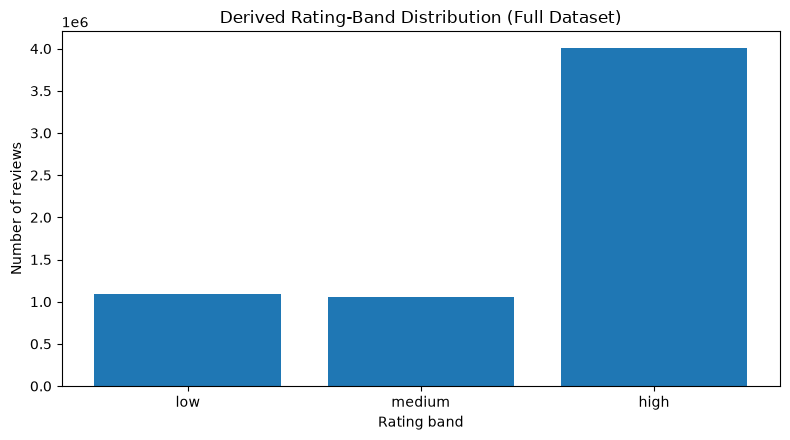

In [8]:
plt.figure(figsize=(8, 4.5))
plt.bar(rating_band_df["rating_band"], rating_band_df["count"])
plt.title("Derived Rating-Band Distribution (Full Dataset)")
plt.xlabel("Rating band")
plt.ylabel("Number of reviews")
plt.tight_layout()
plt.show()


## 4. Recommendation target vocabulary and distribution

The raw labels are shown exactly as found, including missing values. Any spelling normalization or mapping to `recommended`, `not_recommended`, and `no_idea` belongs in a separate, documented preprocessing step.

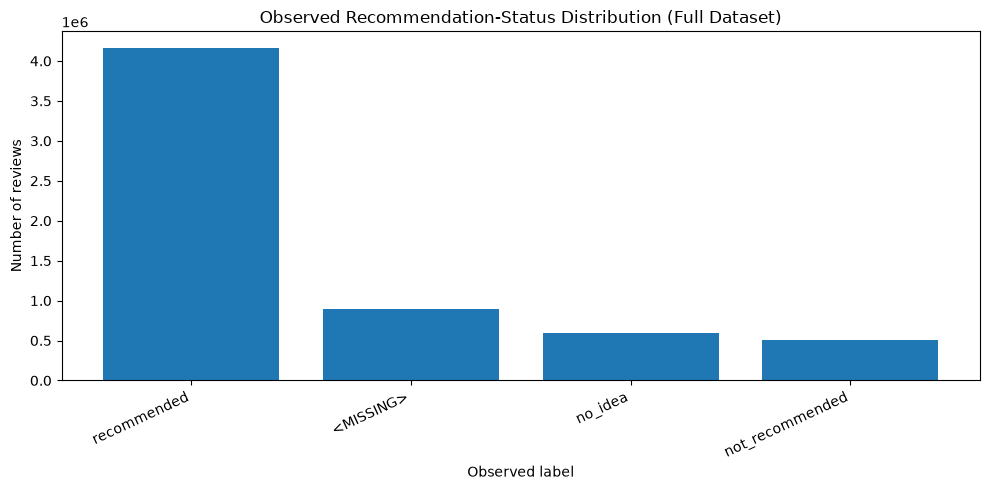

In [9]:
label_plot_df = label_vocabulary_df.copy()
plt.figure(figsize=(10, 5))
plt.bar(label_plot_df["observed_label"].astype(str), label_plot_df["count"])
plt.title("Observed Recommendation-Status Distribution (Full Dataset)")
plt.xlabel("Observed label")
plt.ylabel("Number of reviews")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


## 5. Text-length analysis

Exact global character-length counts are accumulated from the full dataset. Percentiles are estimated from a deterministic bounded sample to avoid holding all review lengths in memory. This limitation is stated explicitly.

,sample_size,min,max,mean,median,p90,p95,p99,word_count_mean_sample,word_count_median_sample,very_short_under_10_chars_sample_pct,very_long_over_1000_chars_sample_pct
0,310000,1,3997,48.213806,29.0,106.0,152.0,293.01,10.048116,6.0,11.000645,0.025806


Text length percentiles/word counts above are estimated from a deterministic sample, not exact full-data percentiles.


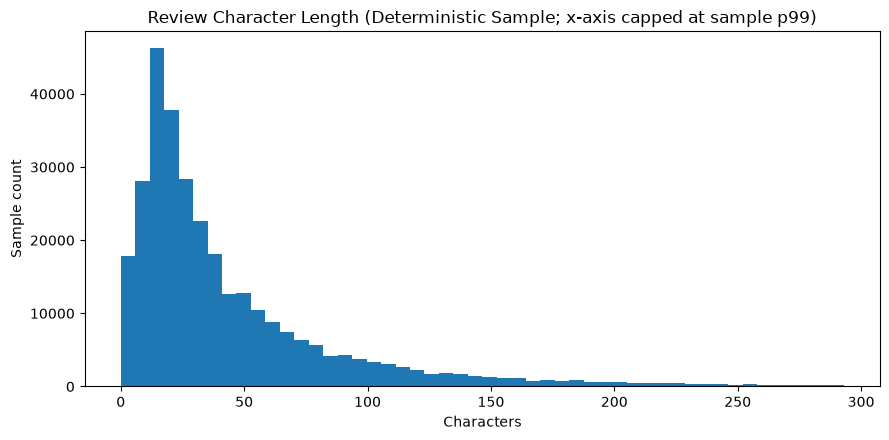

,count,mean,median
label,,,
recommended,42053,44.235917,27.0
<MISSING>,8974,46.589369,25.0
no_idea,6016,58.895445,38.0
not_recommended,4957,72.657051,47.0


<Figure size 1000x500 with 0 Axes>

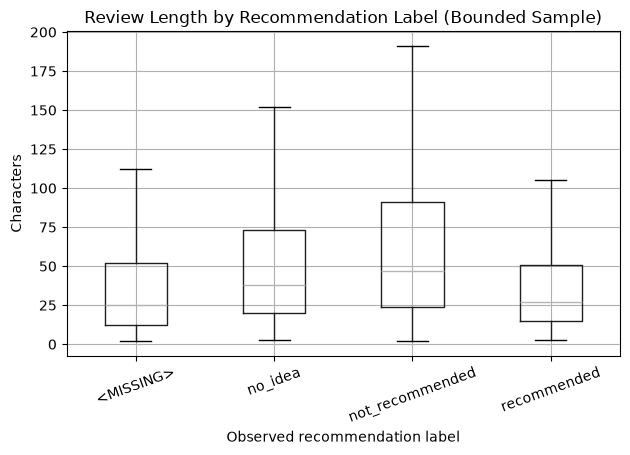

In [11]:
length_sample_parts = []
word_length_sample_parts = []
class_length_samples = []

for chunk in pd.read_csv(COMMENTS_PATH, usecols=["body", "recommendation_status"], chunksize=CHUNK_SIZE, encoding="utf-8-sig"):
    body = chunk["body"].fillna("").astype(str)
    nonempty = body.str.strip().ne("")
    lengths = body.str.len()
    # deterministic per-chunk sample; global moments are not stored as all rows
    candidates = lengths[nonempty]
    if len(candidates):
        length_sample_parts.append(candidates.sample(n=min(5000, len(candidates)), random_state=RANDOM_SEED).to_numpy())
        word_counts = body[nonempty].str.split().str.len()
        word_length_sample_parts.append(word_counts.sample(n=min(5000, len(word_counts)), random_state=RANDOM_SEED).to_numpy())
        temp = pd.DataFrame({"length": lengths[nonempty], "label": chunk.loc[nonempty, "recommendation_status"].astype("string")})
        class_length_samples.append(temp.sample(n=min(1000, len(temp)), random_state=RANDOM_SEED))

length_sample = np.concatenate(length_sample_parts) if length_sample_parts else np.array([])
word_length_sample = np.concatenate(word_length_sample_parts) if word_length_sample_parts else np.array([])
if len(length_sample):
    text_length_summary = pd.DataFrame([{
        "sample_size": len(length_sample), "min": int(length_sample.min()), "max": int(length_sample.max()),
        "mean": float(length_sample.mean()), "median": float(np.median(length_sample)),
        "p90": float(np.quantile(length_sample, .90)), "p95": float(np.quantile(length_sample, .95)),
        "p99": float(np.quantile(length_sample, .99)),
        "word_count_mean_sample": float(word_length_sample.mean()),
        "word_count_median_sample": float(np.median(word_length_sample)),
        "very_short_under_10_chars_sample_pct": float((length_sample < 10).mean() * 100),
        "very_long_over_1000_chars_sample_pct": float((length_sample > 1000).mean() * 100),
    }])
    display(text_length_summary)
    print("Text length percentiles/word counts above are estimated from a deterministic sample, not exact full-data percentiles.")
    plt.figure(figsize=(9, 4.5))
    plt.hist(length_sample, bins=50, range=(0, np.quantile(length_sample, .99)))
    plt.title("Review Character Length (Deterministic Sample; x-axis capped at sample p99)")
    plt.xlabel("Characters")
    plt.ylabel("Sample count")
    plt.tight_layout()
    plt.show()

if class_length_samples:
    class_length_df = pd.concat(class_length_samples, ignore_index=True)
    class_length_df["label"] = class_length_df["label"].fillna("<MISSING>")
    class_length_summary = class_length_df.groupby("label")["length"].agg(["count", "mean", "median"]).sort_values("count", ascending=False)
    display(class_length_summary)
    plt.figure(figsize=(10, 5))
    class_length_df.boxplot(column="length", by="label", showfliers=False, rot=20)
    plt.title("Review Length by Recommendation Label (Bounded Sample)")
    plt.suptitle("")
    plt.xlabel("Observed recommendation label")
    plt.ylabel("Characters")
    plt.tight_layout()
    plt.show()


### Analysing review bodies with less than 5 characters or

In [12]:
from pathlib import Path
from collections import Counter
import pandas as pd
import regex

# Match comments containing only emojis and whitespace
emoji_pattern = regex.compile(
    r"^(?:\s|\p{Extended_Pictographic}|\p{Emoji_Component}|\uFE0F|\u200D)+$"
)

# Initialize counters
total_rows = 0
short_count = 0
emoji_only_count = 0
short_and_emoji_count = 0
empty_count = 0

# Count occurrences of each comment
short_texts = Counter()
emoji_texts = Counter()

# Read the large CSV file in chunks to reduce memory usage
for chunk in pd.read_csv(
    COMMENTS_PATH,
    usecols=["body"],
    chunksize=100_000
):
    total_rows += len(chunk)

    # Remove leading and trailing whitespace
    texts = chunk["body"].fillna("").astype(str).str.strip()

    for text in texts:
        # Count empty comments separately
        if not text:
            empty_count += 1
            continue

        # Check whether the comment contains fewer than 5 characters
        is_short = len(text) < 5

        # Check whether the comment contains only emojis and whitespace
        is_emoji_only = bool(emoji_pattern.fullmatch(text))

        if is_short:
            short_count += 1
            short_texts[text] += 1

        if is_emoji_only:
            emoji_only_count += 1
            emoji_texts[text] += 1

        if is_short and is_emoji_only:
            short_and_emoji_count += 1

# Print the overall statistics
print("Total comments:", f"{total_rows:,}")
print("Empty comments:", f"{empty_count:,}")
print("Comments shorter than 5 characters:", f"{short_count:,}")
print("Emoji-only comments:", f"{emoji_only_count:,}")
print(
    "Comments that are both short and emoji-only:",
    f"{short_and_emoji_count:,}"
)

# Display the 10 most frequent short comments
print("\n" + "=" * 60)
print("Top 10 Most Frequent Comments Shorter Than 5 Characters")
print("=" * 60)

short_top10 = pd.DataFrame(
    short_texts.most_common(10),
    columns=["Comment", "Frequency"]
)

display(short_top10)

# Display the 10 most frequent emoji-only comments
print("\n" + "=" * 60)
print("Top 10 Most Frequent Emoji-Only Comments")
print("=" * 60)

emoji_top10 = pd.DataFrame(
    emoji_texts.most_common(10),
    columns=["Comment", "Frequency"]
)

display(emoji_top10)

Total comments: 6,156,289
Empty comments: 637
Comments shorter than 5 characters: 307,158
Emoji-only comments: 242
Comments that are both short and emoji-only: 161

Top 10 Most Frequent Comments Shorter Than 5 Characters


,Comment,Frequency
0,عالی,134693
1,خوبه,83691
2,خوب,70705
3,عالي,1877
4,زیبا,1808
5,خوب.,1099
6,راضی,859
7,تشکر,633
8,اوکی,522
9,خوبع,466



Top 10 Most Frequent Emoji-Only Comments


,Comment,Frequency
0,👌👌,11
1,👍👍👍,9
2,👍👍👍👍,8
3,👍🏻,8
4,👌👌👌,7
5,👌🏻,6
6,😍😍,6
7,🙏🏻,5
8,👍👍,5
9,👍👍👍👍👍,5


Notes:
- Comments are checked after leading and trailing whitespace is removed.
- Empty comments are counted separately and excluded from the short-comment count.
- A comment can belong to both the short-comment and emoji-only groups.
- The code does not modify or delete any data.

## 7. Products dataset schema and quality

The products file is used for descriptive context and for checking the product relationship. Product-level duplicate IDs are reported, not automatically deleted. Price-related columns are included in schema/missing-value reporting but are not prioritized for the review-text modeling task.

In [16]:
products_header = pd.read_csv(PRODUCTS_PATH, nrows=0, encoding="utf-8-sig")
products_columns = products_header.columns.tolist()
PRODUCTS_REQUIRED = ["id", "title_fa"]
missing_product_columns = [c for c in PRODUCTS_REQUIRED if c not in products_columns]
products_schema_df = pd.DataFrame({"column": products_columns})
display(products_schema_df)
if missing_product_columns:
    raise ValueError(f"Required product columns missing: {missing_product_columns}")

product_rows = 0
product_missing_counts = Counter()
product_id_counts = Counter()
for chunk in pd.read_csv(PRODUCTS_PATH, chunksize=CHUNK_SIZE, encoding="utf-8-sig"):
    product_rows += len(chunk)
    product_missing_counts.update(chunk.isna().sum().to_dict())
    product_id_counts.update(chunk["id"].dropna().tolist())

product_unique_ids = len(product_id_counts)
product_duplicate_ids = sum(count > 1 for count in product_id_counts.values())
product_duplicate_extra_occurrences = sum(count - 1 for count in product_id_counts.values() if count > 1)
product_duplicate_member_rows = sum(count for count in product_id_counts.values() if count > 1)
product_missing_id_count = int(product_missing_counts.get("id", 0))
assert product_rows - product_missing_id_count - product_unique_ids == product_duplicate_extra_occurrences

products_quality_summary = pd.DataFrame([
    ("Total product records", product_rows),
    ("Number of columns", len(products_columns)),
    ("Missing product IDs", product_missing_id_count),
    ("Distinct non-missing product IDs", product_unique_ids),
    ("Distinct duplicated product IDs", product_duplicate_ids),
    ("Extra duplicate occurrences", product_duplicate_extra_occurrences),
    ("Rows belonging to duplicated product IDs", product_duplicate_member_rows),
], columns=["Metric", "Count"])
display(products_quality_summary)

products_missing_report = pd.DataFrame({"column": list(product_missing_counts.keys()), "missing_count": list(product_missing_counts.values())})
products_missing_report["missing_percentage"] = (products_missing_report["missing_count"] / product_rows * 100).round(3)
display(products_missing_report.sort_values("missing_count", ascending=False))


,column
0,id
1,title_fa
2,Rate
3,Rate_cnt
4,Category1
5,Category2
6,Brand
7,Price
8,Seller
9,Is_Fake


,Metric,Count
0,Total product records,1283496
1,Number of columns,12
2,Missing product IDs,0
3,Distinct non-missing product IDs,948352
4,Distinct duplicated product IDs,258718
5,Extra duplicate occurrences,335144
6,Rows belonging to duplicated product IDs,593862


,column,missing_count,missing_percentage
5,Category2,210108,16.370
8,Seller,223,0.017
0,id,0,0.000
1,title_fa,0,0.000
3,Rate_cnt,0,0.000
2,Rate,0,0.000
6,Brand,0,0.000
4,Category1,0,0.000
7,Price,0,0.000
9,Is_Fake,0,0.000


In [ ]:
products = pd.read_csv(
    PRODUCTS_PATH,
    usecols=["id", "title_fa", "Rate", "Rate_cnt",
             "Category1", "Category2", "Brand", "Price",
             "Seller", "Is_Fake", "min_price_last_month",
             "sub_category"]
)

# Find every row whose product ID appears more than once
duplicated_rows = products[
    products["id"].duplicated(keep=False)
]

print("Rows with duplicated IDs:", len(duplicated_rows))

# Inspect several duplicated IDs
sample_ids = duplicated_rows["id"].drop_duplicates().head(5)

for product_id in sample_ids:
    print(f"\n--- Product ID: {product_id} ---")
    display(
        products[products["id"] == product_id]
        .sort_values("id")
    )

C:\Users\Setayesh\AppData\Local\Temp\ipykernel_14404\2666147133.py:1: DtypeWarning: Columns (5: Category2) have mixed types. Specify dtype option on import or set low_memory=False.
  products = pd.read_csv(


Rows with duplicated IDs: 593862

--- Product ID: 1452939 ---


,id,title_fa,Rate,Rate_cnt,Category1,Category2,Brand,Price,Seller,Is_Fake,min_price_last_month,sub_category
25,1452939,آبسلانگ مدل 1002 بسته 30 عددی,76,166,آبسلانگ,NaN,متفرقه,245000,سلامت ساز راد,False,0,beauty
26,1452939,آبسلانگ مدل 1002 بسته 30 عددی,76,166,آبسلانگ,NaN,متفرقه,245000,سلامت ساز راد,False,0,beauty



--- Product ID: 10420922 ---


,id,title_fa,Rate,Rate_cnt,Category1,Category2,Brand,Price,Seller,Is_Fake,min_price_last_month,sub_category
72,10420922,مداد ابرو پیپا مدل پرفکت شماره 104,0,0,آرایش ابرو,مداد ابرو,متفرقه,5440000,سی سی,False,0,beauty
73,10420922,مداد ابرو پیپا مدل پرفکت شماره 104,0,0,آرایش ابرو,مداد ابرو,متفرقه,5440000,سی سی,False,0,beauty



--- Product ID: 9803517 ---


... (31 outputs left out)


--- Product ID: 3853656 ---


,id,title_fa,Rate,Rate_cnt,Category1,Category2,Brand,Price,Seller,Is_Fake,min_price_last_month,sub_category
441,3853656,مداد ابرو بلیتا شماره 588,86,28,آرایش ابرو,مداد ابرو,بلیتا,687900,لشم,False,0,beauty
782,3853656,مداد ابرو بلیتا شماره 588,86,28,آرایش ابرو,مداد ابرو,بلیتا,687900,لشم,False,0,beauty



--- Product ID: 10764063 ---


,id,title_fa,Rate,Rate_cnt,Category1,Category2,Brand,Price,Seller,Is_Fake,min_price_last_month,sub_category
442,10764063,کیت رنگ ابرو ویتامول شماره BG حجم 30 میلی لیتر رنگ بلوند طلایی روشن,0,0,آرایش ابرو,رنگ ابرو,ویتامول,690000,فروشگاه ملکه طلایی,False,0,beauty
783,10764063,کیت رنگ ابرو ویتامول شماره BG حجم 30 میلی لیتر رنگ بلوند طلایی روشن,0,0,آرایش ابرو,رنگ ابرو,ویتامول,690000,فروشگاه ملکه طلایی,False,0,beauty


### Relationship check: comments `product_id` → products `id`

This is a referential-integrity audit only. It does not merge product metadata into model inputs.

In [18]:
known_product_ids = set(product_id_counts.keys())
comment_product_ids = set()
comment_product_id_rows = 0
unmatched_product_id_rows = 0
for chunk in pd.read_csv(COMMENTS_PATH, usecols=["product_id"], chunksize=CHUNK_SIZE, encoding="utf-8-sig"):
    ids = chunk["product_id"].dropna()
    comment_product_id_rows += len(ids)
    unmatched_product_id_rows += int((~ids.isin(known_product_ids)).sum())
    comment_product_ids.update(ids.tolist())

relationship_summary = pd.DataFrame([{
    "nonmissing_comment_product_id_rows": comment_product_id_rows,
    "distinct_product_ids_referenced_by_comments": len(comment_product_ids),
    "distinct_referenced_product_ids_missing_from_products": len(comment_product_ids - known_product_ids),
    "comment_rows_with_product_id_not_found_in_products": unmatched_product_id_rows,
}])
display(relationship_summary)


,nonmissing_comment_product_id_rows,distinct_product_ids_referenced_by_comments,distinct_referenced_product_ids_missing_from_products,comment_rows_with_product_id_not_found_in_products
0,6156289,331599,0,0


## 8. Audit conclusions and modeling implications

Use the measured tables above to confirm or revise these evidence-based decisions. These are protocol conclusions, not a claim that any records have already been cleaned.

## Audit Conclusions

1. The raw CSV files remain unchanged. This notebook performs an audit only; no records are excluded or corrected.

2. The observed recommendation label vocabulary must be mapped to the three canonical classes in a separate, documented preprocessing step.

3. The raw `rate` column is used only for auditing and target construction. It must never be included as a model feature.

4. Missing, malformed, and out-of-range `rate` values must be masked for the `rating_band` head and counted in the quality report.

5. Repeated review IDs require an explicit policy. This notebook reports duplicate IDs but does not silently deduplicate records.

6. Product concentration supports using product-grouped train/validation/test splits to reduce data leakage.

7. Text-length sample percentiles can inform the choice of `max_length`. The selected limit must be justified and documented in the modeling notebook.

8. Only `body` is permitted as model text input. The following fields must not be used as model features: `title`, `rate`, `recommendation_status`, `product_id`, seller metadata, timestamps, likes/dislikes, `advantages`, and `disadvantages`.

## Sampling and Coverage Statement

- **Random seed:** `42`
- **Chunk size:** `100,000` rows

### Sampling Strategy

- **Initial audit sample:** Within each chunk, sample up to 200 non-empty rows.
- **Text-length quantile sample:** Sample up to 5,000 valid rows per chunk.
- **Class-wise text-length sample:** Sample up to 1,000 rows per chunk.

### Coverage and Statistical Reliability

- **Full-dataset counts:** Schema information, missing-value counts, exact label counts, duplicate ID counts, and product concentration counts are computed over the full CSV files.
- **Sampled statistics:** Text-length percentiles, word counts, class-wise text-length plots, and displayed review examples are based on deterministic, bounded samples.

### Important Note

Full-dataset counts represent the complete CSV files, whereas sampled statistics describe only the selected samples and may not exactly reflect the full dataset distribution.

## 9. Quality-Gate Checklist Before Modeling

### 9.1. Schema and Dataset Integrity

- [x] columns are present in both the comments and products datasets.
- [x] Full-dataset row counts and schema information have been inspected.
- [x] Missing-value counts have been reviewed for the main columns.
- [ ] Data types and parsing assumptions have been validated and documented.
- [x] Raw source CSV files remain unchanged; all cleaning operations must be performed on derived data.
- [ ] Every cleaning exclusion or correction is recorded in a cleaning log or manifest.

### 9.2. IDs and Duplicate Records

- [x] Missing and duplicate comment IDs have been counted.
- [x] Duplicate product IDs and their concentration have been examined.
- [ ] A duplicate-ID policy has been decided and documented; no silent deletion.
- [ ] Repeated product records have been classified as identical or conflicting before any action is taken.
- [x] Exact repeated review texts have been audited, including cases with conflicting recommendation labels.
- [ ] A policy for repeated review texts across products and dataset splits has been documented.
- [ ] Duplicate handling has been implemented consistently without removing records solely because an ID or body is repeated.

### 9.3. Missing, Short, and Unusual Review Texts

- [x] Missing and empty review bodies have been examined.
- [x] Review-length statistics have been inspected, including minimum, maximum, mean, median, and upper percentiles.
- [x] The frequency of reviews shorter than five characters has been calculated and reviewed.
- [x] Emoji-only reviews and their most frequent examples have been examined.
- [ ] A documented policy defines how empty, short, emoji-only, and otherwise invalid texts are handled for each task.
- [ ] Text normalization rules are documented and applied consistently without changing the raw source data.

### 9.4. Target Labels and Missing Targets

- [x] Exact recommendation-label counts have been computed on the full comments dataset.
- [x] The observed label vocabulary has been reviewed, including `recommended`, `not_recommended`, `no_idea`, and missing values..
- [ ] Missing targets are masked per task/head rather than dropping a row that has another valid target.
- [x] Repeated review texts with conflicting labels have been investigated before any relabeling or exclusion.

### 9.5. Rating Quality and Rating-Band Definition

- [x] Rating-value frequencies have been inspected.
- [x] Zero ratings and their temporal distribution have been investigated.
- [x] The anomalous value `2500` has been identified for review.
- [x] Malformed and out-of-range rating counts have been reviewed and documented.
- [x] The policy for `rate = 0` has been explicitly documented; zero is not automatically treated as a genuine rating.
- [ ] The anomalous `rate = 2500` record has been investigated without silently correcting or deleting it.
- [ ] Recommendation labels are not modified solely because a rating is zero or missing.
- [ ] `rating_band` thresholds are fixed at low `[0, 2.5)`, medium `[2.5, 4.0)`, and high `[4.0, 5.0]`, unless evidence and approval justify a change.
- [ ] Invalid or unavailable ratings are excluded from the rating-band loss and evaluation, while the same row may remain usable for another task.

### 9.6. Dataset Coverage and Sampling

- [x] Full-dataset counts have been distinguished from statistics computed on samples.
- [x] The sampling seed and chunk size have been documented.
- [x] The initial audit sample, text-length quantile sample, and class-wise text-length sample strategies have been documented.
- [ ] Sampled statistics are clearly identified as estimates and are not reported as exact full-dataset counts.
- [ ] Sampling results are reproducible using the documented random seed and sampling rules.
- [ ] Review examples and text-length distributions have been checked for obvious sampling or parsing artifacts.

### 9.7. Metadata and Potential Leakage

- [x] The relationship between `is_buyer` and missing `seller_title` has been examined.
- [ ] Seller-related metadata and other non-text fields are excluded from model inputs unless a separate, explicitly approved experiment permits them.
- [ ] Only `body` is used as the review-text input.
- [ ] `title`, `rate`, `recommendation_status`, `product_id`, seller metadata, timestamps, likes/dislikes, advantages, and disadvantages are not used as model features.
- [ ] `product_id` is used only for grouping records during splitting, not as a predictive feature.
- [ ] No target-derived information or post-outcome metadata leaks into model inputs.
- [ ] Any derived text features are calculated only from permitted input text.

**Important:** A checked box indicates that the corresponding check has been completed and its outcome reviewed. It does not automatically mean that the data passed the check or that a policy has been approved. Checks marked above should be updated only when supported by notebook outputs, documented decisions, or verified execution results.


## A1–A7 completion supplement — full-dataset analyses

The existing cells above perform the initial quality-gate scan. The following cells add the missing A1–A7 analyses. They use the same `COMMENTS_PATH`, `PRODUCTS_PATH`, `CHUNK_SIZE`, and `RANDOM_SEED` configuration. Raw files are never modified. Global statistics are computed from the complete CSV in chunks; samples are used only for examples.

In [26]:
# Confirm schema and report file metadata using parser-based row counts, not physical lines.
from pathlib import Path
import sqlite3, tempfile, os, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

assert COMMENTS_PATH.exists(), f"Missing file: {COMMENTS_PATH.resolve()}"
assert PRODUCTS_PATH.exists(), f"Missing file: {PRODUCTS_PATH.resolve()}"
comments_cols = pd.read_csv(COMMENTS_PATH, nrows=0).columns.tolist()
products_cols = pd.read_csv(PRODUCTS_PATH, nrows=0).columns.tolist()
print("Comments file bytes:", COMMENTS_PATH.stat().st_size)
print("Products file bytes:", PRODUCTS_PATH.stat().st_size)
print("Comments columns:", len(comments_cols), comments_cols)
print("Products columns:", len(products_cols), products_cols)

Comments file bytes: 1278526959
Products file bytes: 258733765
Comments columns: 15 ['id', 'title', 'body', 'created_at', 'rate', 'recommendation_status', 'is_buyer', 'product_id', 'advantages', 'disadvantages', 'likes', 'dislikes', 'seller_title', 'seller_code', 'true_to_size_rate']
Products columns: 12 ['id', 'title_fa', 'Rate', 'Rate_cnt', 'Category1', 'Category2', 'Brand', 'Price', 'Seller', 'Is_Fake', 'min_price_last_month', 'sub_category']


### A1. Product metadata, unique sellers, and product review-count distribution

In [27]:
# Full products CSV scan. Rate_cnt is product metadata, not a model feature.
product_rows = 0
product_ids = set()
seller_values = set()
product_missing = {}
product_review_counts = []
product_id_frequency = {}
for chunk in pd.read_csv(PRODUCTS_PATH, chunksize=CHUNK_SIZE, dtype={"id":"string", "Seller":"string", "Rate_cnt":"string"}, low_memory=False):
    product_rows += len(chunk)
    for col in chunk.columns:
        product_missing[col] = product_missing.get(col, 0) + int(chunk[col].isna().sum())
    product_ids.update(chunk["id"].dropna().astype(str))
    if "Seller" in chunk:
        seller_values.update(chunk["Seller"].dropna().astype(str))
    if "Rate_cnt" in chunk:
        product_review_counts.extend(pd.to_numeric(chunk["Rate_cnt"], errors="coerce").dropna().tolist())
    vc = chunk["id"].dropna().astype(str).value_counts()
    for k, v in vc.items(): product_id_frequency[k] = product_id_frequency.get(k, 0) + int(v)
print(f"Product parser rows: {product_rows:,}")
print(f"Unique product IDs: {len(product_ids):,}")
print(f"Unique nonmissing Seller strings: {len(seller_values):,}")
print("Product missing values:")
display(pd.DataFrame([{"column":k,"missing_count":v,"missing_percent":100*v/product_rows} for k,v in product_missing.items()]).sort_values("missing_count",ascending=False))
if product_review_counts:
    display(pd.Series(product_review_counts, name="Rate_cnt").describe(percentiles=[.5,.9,.95,.99]).to_frame())

Product parser rows: 1,283,496
Unique product IDs: 948,352
Unique nonmissing Seller strings: 18,584
Product missing values:


,column,missing_count,missing_percent
5,Category2,210108,16.369977
8,Seller,223,0.017374
0,id,0,0.000000
1,title_fa,0,0.000000
3,Rate_cnt,0,0.000000
2,Rate,0,0.000000
6,Brand,0,0.000000
4,Category1,0,0.000000
7,Price,0,0.000000
9,Is_Fake,0,0.000000


,Rate_cnt
count,1.283496e+06
mean,2.073829e+01
std,2.182101e+02
min,0.000000e+00
50%,0.000000e+00
90%,1.500000e+01
95%,4.400000e+01
99%,3.670000e+02
max,3.043800e+04


### A2. Missingness in recommendation labels versus metadata

In [28]:
# Full-data cross-tabulations: label missingness by is_buyer and rating group.
parts = []
usecols = [c for c in ["recommendation_status", "is_buyer", "rate", "product_id", "seller_code"] if c in comments_cols]
for chunk in pd.read_csv(COMMENTS_PATH, chunksize=CHUNK_SIZE, usecols=usecols, dtype={c:"string" for c in usecols}, low_memory=False):
    miss = chunk["recommendation_status"].isna() | chunk["recommendation_status"].str.strip().eq("")
    for col in ["is_buyer", "seller_code"]:
        if col in chunk:
            tmp = pd.DataFrame({"group":chunk[col].fillna("<MISSING>"),"label_missing":miss})
            tab = tmp.groupby(["group","label_missing"],dropna=False).size().rename("count").reset_index()
            tab["metadata"] = col; parts.append(tab)
    if "rate" in chunk:
        rate = pd.to_numeric(chunk["rate"], errors="coerce")
        rg = pd.cut(
        rate,
        bins=[-np.inf, 0, 0.0000001, 1, 2, 3, 4, 5, np.inf],
        labels=["<0", "0", "(0,1]", "(1,2]", "(2,3]", "(3,4]", "(4,5]", ">5"]
    ).astype("string").fillna("<INVALID_OR_MISSING>")
        tmp = pd.DataFrame({"group":rg,"label_missing":miss})
        tab = tmp.groupby(["group","label_missing"],dropna=False).size().rename("count").reset_index()
        tab["metadata"] = "rate_group"; parts.append(tab)
missingness_cross_tabs = pd.concat(parts,ignore_index=True) if parts else pd.DataFrame()
if not missingness_cross_tabs.empty:
    display(missingness_cross_tabs)
# Product concentration of missing labels, aggregated over the complete file.
prod_missing_counts = {}
for chunk in pd.read_csv(COMMENTS_PATH,chunksize=CHUNK_SIZE,usecols=["recommendation_status","product_id"],dtype={"recommendation_status":"string","product_id":"string"}):
    m = chunk["recommendation_status"].isna() | chunk["recommendation_status"].str.strip().eq("")
    vc = chunk.loc[m,"product_id"].fillna("<MISSING>").value_counts()
    for k,v in vc.items(): prod_missing_counts[k]=prod_missing_counts.get(k,0)+int(v)
print("Products with most missing recommendation labels:")
display(pd.Series(prod_missing_counts).sort_values(ascending=False).head(20).rename("missing_label_rows").to_frame())

,group,label_missing,count,metadata
0,False,True,4483,is_buyer
1,True,False,85997,is_buyer
2,True,True,9520,is_buyer
3,3MKUM,False,69,seller_code
4,3MKUM,True,10,seller_code
...,...,...,...,...
323434,"(3,4]",True,2179,rate_group
323435,"(4,5]",False,18515,rate_group
323436,"(4,5]",True,6494,rate_group
323437,<0,False,4631,rate_group


Products with most missing recommendation labels:


,missing_label_rows
3737956,191
6849325,188
4523418,179
5384740,172
6741006,170
4291430,139
12294347,123
5677781,117
984129,111
12292360,110


### A3. Full-data rating-band distribution and rate-versus-label relationship

RATING DATA QUALITY
-------------------
Missing ratings:     0
Non-numeric ratings: 0
Out-of-range ratings:1

Valid ratings: 6,156,288
Unique values: 177
Fractional values: 228128


,rate
count,6.156288e+06
mean,3.647880e+00
std,1.566601e+00
min,0.000000e+00
1%,0.000000e+00
5%,0.000000e+00
25%,3.000000e+00
50%,4.000000e+00
75%,5.000000e+00
90%,5.000000e+00



RATING-BAND DISTRIBUTION
-----------------------


,rating_band,count,ordinal_code,percent_of_valid_rates
0,low,1092329,0,17.74
1,medium,1059054,1,17.20
2,high,4004905,2,65.05


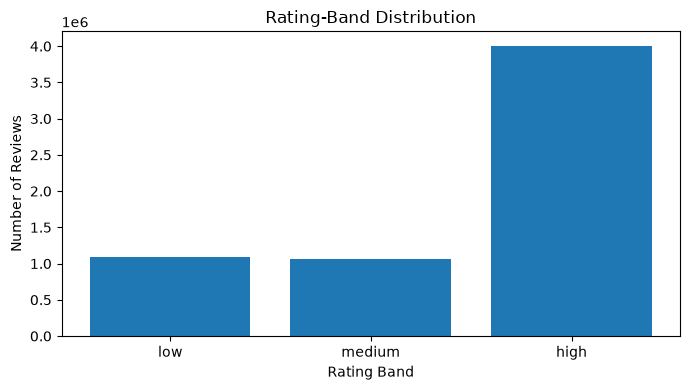


RECOMMENDATION-LABEL DISTRIBUTION
--------------------------------


,label,count,percent_all_rows
0,recommended,4162839,67.62
1,<MISSING>,894426,14.53
2,no_idea,594121,9.65
3,not_recommended,504903,8.20


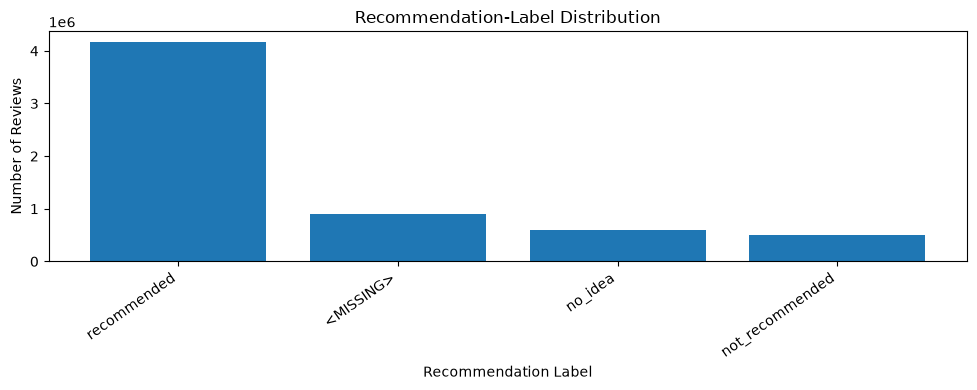


LABEL × RATING BAND — COUNTS


rating_band,high,low,medium
label,,,
<MISSING>,682505,100714,111207
no_idea,101844,104215,388062
not_recommended,12635,424398,67870
recommended,3207921,463002,491915



PERCENTAGE WITHIN EACH LABEL (%)


rating_band,high,low,medium
label,,,
<MISSING>,76.31,11.26,12.43
no_idea,17.14,17.54,65.32
not_recommended,2.50,84.06,13.44
recommended,77.06,11.12,11.82



PERCENTAGE WITHIN EACH RATING BAND (%)


label,<MISSING>,no_idea,not_recommended,recommended
rating_band,,,,
high,17.04,2.54,0.32,80.10
low,9.22,9.54,38.85,42.39
medium,10.50,36.64,6.41,46.45



PERCENTAGE OF ALL DATASET ROWS (%)


rating_band,high,low,medium
label,,,
<MISSING>,11.09,1.64,1.81
no_idea,1.65,1.69,6.30
not_recommended,0.21,6.89,1.10
recommended,52.11,7.52,7.99


In [29]:
# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

RATE_COLUMN = "rate"
LABEL_COLUMN = "recommendation_status"

RATING_BANDS = {
    "low": (0, 2.5),
    "medium": (2.5, 4),
    "high": (4, 5),
}

ORDINAL_CODES = {
    "low": 0,
    "medium": 1,
    "high": 2,
}

INVALID_BAND = "<INVALID_OR_MISSING>"
MISSING_LABEL = "<MISSING>"
BLANK_LABEL = "<BLANK>"


# --------------------------------------------------
# 2. Initialize counters
# --------------------------------------------------

band_counts = {band: 0 for band in RATING_BANDS}
label_counts = {}
label_band_counts = {}

rate_missing = 0
rate_non_numeric = 0
rate_out_of_range = 0

rate_values = []


# --------------------------------------------------
# 3. Read and process the dataset in chunks
# --------------------------------------------------

for chunk in pd.read_csv(
    COMMENTS_PATH,
    usecols=[RATE_COLUMN, LABEL_COLUMN],
    chunksize=CHUNK_SIZE,
    dtype={
        RATE_COLUMN: "string",
        LABEL_COLUMN: "string",
    },
    low_memory=False,
    encoding="utf-8-sig",
):

    # 3.1 Clean and convert rating values
    raw_rate = chunk[RATE_COLUMN].str.strip()

    missing_mask = raw_rate.isna() | raw_rate.eq("")
    numeric_rate = pd.to_numeric(
        raw_rate.mask(missing_mask),
        errors="coerce",
    )

    rate_missing += int(missing_mask.sum())
    rate_non_numeric += int(
        (~missing_mask & numeric_rate.isna()).sum()
    )

    out_of_range_mask = (
        numeric_rate.notna()
        & ~numeric_rate.between(0, 5)
    )
    rate_out_of_range += int(out_of_range_mask.sum())

    valid_rate_mask = numeric_rate.between(0, 5)

    # Keep valid ratings for descriptive statistics
    valid_values = numeric_rate[valid_rate_mask].to_numpy(
        dtype=float
    )

    if len(valid_values) > 0:
        rate_values.append(valid_values)

    # 3.2 Assign rating bands
    rating_band = pd.Series(
        INVALID_BAND,
        index=chunk.index,
        dtype="string",
    )

    rating_band.loc[
        valid_rate_mask & (numeric_rate < 2.5)
    ] = "low"

    rating_band.loc[
        valid_rate_mask
        & (numeric_rate >= 2.5)
        & (numeric_rate < 4)
    ] = "medium"

    rating_band.loc[
        valid_rate_mask
        & (numeric_rate >= 4)
    ] = "high"

    # Count valid ratings in each band
    for band, count in rating_band[
        rating_band.isin(RATING_BANDS)
    ].value_counts().items():
        band_counts[band] += int(count)

    # 3.3 Clean recommendation labels
    labels = chunk[LABEL_COLUMN].str.strip()

    labels = labels.fillna(MISSING_LABEL)
    labels = labels.mask(labels.eq(""), BLANK_LABEL)

    # Count all labels
    for label, count in labels.value_counts().items():
        label_counts[label] = (
            label_counts.get(label, 0) + int(count)
        )

    # 3.4 Count each label-rating-band combination
    chunk_counts = pd.DataFrame({
        "label": labels,
        "rating_band": rating_band,
    }).value_counts()

    for (label, band), count in chunk_counts.items():
        key = (label, band)
        label_band_counts[key] = (
            label_band_counts.get(key, 0) + int(count)
        )


# --------------------------------------------------
# 4. Rating data quality and descriptive statistics
# --------------------------------------------------

print("RATING DATA QUALITY")
print("-------------------")
print(f"Missing ratings:     {rate_missing:,}")
print(f"Non-numeric ratings: {rate_non_numeric:,}")
print(f"Out-of-range ratings:{rate_out_of_range:,}")

if rate_values:
    all_valid_rates = np.concatenate(rate_values)

    print(f"\nValid ratings: {len(all_valid_rates):,}")
    print(f"Unique values: {len(np.unique(all_valid_rates)):,}")
    print(
        "Fractional values:",
        int(
            (~np.isclose(
                all_valid_rates,
                np.round(all_valid_rates),
            )).sum()
        ),
    )

    display(
        pd.Series(
            all_valid_rates,
            name="rate",
        ).describe(
            percentiles=[
                0.01, 0.05, 0.25, 0.50,
                0.75, 0.90, 0.95, 0.99,
            ]
        ).to_frame()
    )


# --------------------------------------------------
# 5. Rating-band distribution
# --------------------------------------------------

band_df = pd.DataFrame([
    {
        "rating_band": band,
        "count": count,
        "ordinal_code": ORDINAL_CODES[band],
    }
    for band, count in band_counts.items()
])

total_valid_rates = sum(band_counts.values())

band_df["percent_of_valid_rates"] = (
    band_df["count"] / max(total_valid_rates, 1) * 100
)

print("\nRATING-BAND DISTRIBUTION")
print("-----------------------")
display(band_df.round(2))

plt.figure(figsize=(7, 4))
plt.bar(band_df["rating_band"], band_df["count"])
plt.title("Rating-Band Distribution")
plt.xlabel("Rating Band")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 6. Recommendation-label distribution
# --------------------------------------------------

label_df = pd.DataFrame([
    {
        "label": label,
        "count": count,
    }
    for label, count in label_counts.items()
])

total_rows = label_df["count"].sum()

label_df["percent_all_rows"] = (
    label_df["count"] / max(total_rows, 1) * 100
)

label_df = label_df.sort_values(
    "count",
    ascending=False,
)

print("\nRECOMMENDATION-LABEL DISTRIBUTION")
print("--------------------------------")
display(label_df.round(2))

plt.figure(figsize=(10, 4))
plt.bar(label_df["label"], label_df["count"])
plt.xticks(rotation=35, ha="right")
plt.title("Recommendation-Label Distribution")
plt.xlabel("Recommendation Label")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


# --------------------------------------------------
# 7. Label and rating-band relationship
# --------------------------------------------------

joint = pd.DataFrame([
    {
        "label": label,
        "rating_band": band,
        "count": count,
    }
    for (label, band), count in label_band_counts.items()
    if band != INVALID_BAND
])

if not joint.empty:

    # Percentage within each label
    joint["percent_within_label"] = (
        joint["count"]
        / joint.groupby("label")["count"].transform("sum")
        * 100
    )

    # Percentage within each rating band
    joint["percent_within_band"] = (
        joint["count"]
        / joint.groupby("rating_band")["count"].transform("sum")
        * 100
    )

    # Percentage of all dataset rows
    joint["percent_all_rows"] = (
        joint["count"] / max(total_rows, 1) * 100
    )

    # 7.1 Counts
    print("\nLABEL × RATING BAND — COUNTS")
    display(
        joint.pivot(
            index="label",
            columns="rating_band",
            values="count",
        ).fillna(0).astype("int64")
    )

    # 7.2 Percentage within each label
    print("\nPERCENTAGE WITHIN EACH LABEL (%)")
    display(
        joint.pivot(
            index="label",
            columns="rating_band",
            values="percent_within_label",
        ).fillna(0).round(2)
    )

    # 7.3 Percentage within each rating band
    print("\nPERCENTAGE WITHIN EACH RATING BAND (%)")

    display(
        joint.pivot(
            index="rating_band",
            columns="label",
            values="percent_within_band",
        ).fillna(0).round(2)
    )

    # 7.4 Percentage of all dataset rows
    print("\nPERCENTAGE OF ALL DATASET ROWS (%)")
    display(
        joint.pivot(
            index="label",
            columns="rating_band",
            values="percent_all_rows",
        ).fillna(0).round(2)
    )


## Interpretation of Tables

### 1. Count of Ratings by Recommendation Status (LABEL × RATING BAND — COUNTS)

This table shows the number of reviews in each rating band (`high`, `medium`, and `low`) for every recommendation status. It provides the raw counts without calculating percentages.

### 2. Rating Distribution Within Each Recommendation Label ( PERCENTAGE WITHIN EACH LABEL )

This table shows the percentage of reviews in each rating band for a given recommendation status. Each row sums to approximately 100%, allowing us to compare the rating distribution across recommendation labels.

### 3. Recommendation Label Distribution Within Each Rating Band ( PERCENTAGE WITHIN EACH RATING BAND )

This table shows the percentage of reviews belonging to each recommendation status within each rating band. Each column sums to approximately 100%, helping us understand how recommendation labels are distributed among high-, medium-, and low-rated reviews.

### 4. Percentage of All Reviews (PERCENTAGE OF ALL DATASET ROWS)

This table shows the percentage of the entire dataset represented by each combination of rating band and recommendation status. Unlike the previous tables, the percentages are calculated using the total number of reviews as the denominator, so the values across the table do not necessarily sum to 100%.

### Number of reviews with a rate of 0 or unrecorded points but 'recommended' status

In [22]:
count_unrated_recommended = 0
total_recommended = 0
total_rows = 0

for chunk in pd.read_csv(
    COMMENTS_PATH,
    chunksize=CHUNK_SIZE,
    usecols=["rate", "recommendation_status"]
):
    rate = pd.to_numeric(chunk["rate"], errors="coerce")
    status = chunk["recommendation_status"]

   # Unrecorded score: zero or an empty value
    unrated = rate.isna() | (rate == 0)

    # recommended state
    recommended = status == "recommended"

    count_unrated_recommended += int((unrated & recommended).sum())
    total_recommended += int(recommended.sum())
    total_rows += len(chunk)

print(f"All Records {total_rows:,}")
print(f"Number of reviews with 'recommended' status: {total_recommended:,}")
print(f"Number of unrecorded rate or with a rate of 0 with 'recommended' status: {count_unrated_recommended:,}")

print(
    f"Percentage "
    f"{count_unrated_recommended / total_rows * 100:.2f}%"
    if total_rows else "There is no such record"
)

print(
    f"Percentage of recommended reviews:"
    f"{count_unrated_recommended / total_recommended * 100:.2f}%"
    if total_recommended else "No data with the status 'recommended' exists."
)

print(f"Percentage of recommended reviews among all rows: "
      f"{total_recommended / total_rows * 100:.2f}%")

print(f"Percentage of unrated/zero-rate recommended reviews "
      f"among all rows: "
      f"{count_unrated_recommended / total_rows * 100:.2f}%")

print(f"Percentage of unrated/zero-rate reviews "
      f"among recommended reviews: "
      f"{count_unrated_recommended / total_recommended * 100:.2f}%")

All Records 6,156,289
Number of reviews with 'recommended' status: 4,162,839
Number of unrecorded rate or with a rate of 0 with 'recommended' status: 425,745
Percentage 6.92%
Percentage of recommended reviews:10.23%
Percentage of recommended reviews among all rows: 67.62%
Percentage of unrated/zero-rate recommended reviews among all rows: 6.92%
Percentage of unrated/zero-rate reviews among recommended reviews: 10.23%


### Inspecting the percentage of labels for rate = 0

In [23]:
rate_zero_counts = {
    "recommended": 0,
    "not_recommended": 0,
    "no_idea": 0,
    "missing_label": 0,
    "other_label": 0,
}

total_rate_zero = 0

for chunk in pd.read_csv(
    COMMENTS_PATH,
    usecols=["rate", "recommendation_status"],
    chunksize=CHUNK_SIZE,
    encoding="utf-8-sig",
    low_memory=False
):
    rate = pd.to_numeric(chunk["rate"], errors="coerce")
    labels = (
        chunk["recommendation_status"]
        .fillna("")
        .astype(str)
        .str.strip()
        .str.lower()
    )

    mask = rate.eq(0)
    zero_rate_labels = labels[mask]

    total_rate_zero += int(mask.sum())

    rate_zero_counts["recommended"] += int(
        zero_rate_labels.eq("recommended").sum()
    )
    rate_zero_counts["not_recommended"] += int(
        zero_rate_labels.eq("not_recommended").sum()
    )
    rate_zero_counts["no_idea"] += int(
        zero_rate_labels.eq("no_idea").sum()
    )
    rate_zero_counts["missing_label"] += int(
        zero_rate_labels.eq("").sum()
    )
    rate_zero_counts["other_label"] += int(
        (~zero_rate_labels.isin([
            "recommended",
            "not_recommended",
            "no_idea",
            ""
        ])).sum()
    )

results = pd.DataFrame.from_dict(
    rate_zero_counts,
    orient="index",
    columns=["count"]
)

results.index.name = "label"

results["percent_of_rate_zero"] = (
    results["count"] / total_rate_zero * 100
    if total_rate_zero > 0 else 0
)

print(f"Total reviews with rate = 0: {total_rate_zero:,}")
display(results.round(2))


Total reviews with rate = 0: 529,098


,count,percent_of_rate_zero
label,,
recommended,425745,80.47
not_recommended,57424,10.85
no_idea,20570,3.89
missing_label,25359,4.79
other_label,0,0.00


### A4. Full-data text-length statistics and class comparison

,measure,count,mean,median,std,min,p75,p90,p95,p99,max,very_short,very_long
0,characters,6156289,48.393344,29.0,64.349205,0,57.0,106.0,152.0,297.0,4000,763590,59936
1,words,6156289,10.086071,6.0,13.365469,0,12.0,22.0,32.0,62.0,908,1023154,16012


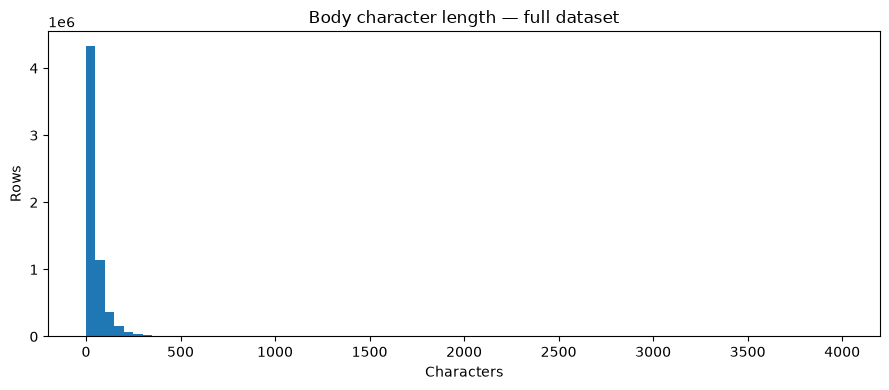

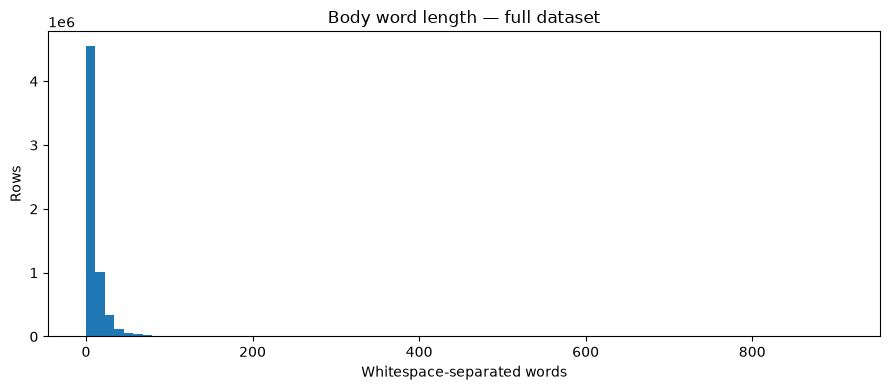

,label,count,mean_chars,median_chars,p90_chars,p95_chars
1,recommended,4162839,44.247707,27.0,95.0,136.0
2,<MISSING>,894426,46.408570,25.0,105.0,155.0
3,no_idea,594121,59.297926,38.0,129.0,181.0
0,not_recommended,504903,73.257941,48.0,159.0,217.0


In [30]:
char_all=[]
word_all=[]
class_lengths={}
for chunk in pd.read_csv(
    COMMENTS_PATH,
    chunksize=CHUNK_SIZE,
    usecols=["body","recommendation_status"],
    dtype={"recommendation_status":"string"},
    low_memory=False
    ):
        body=chunk["body"].fillna("").astype(str)
        chars=body.str.len().to_numpy(dtype=np.int32)
        words=body.str.split().str.len().to_numpy(dtype=np.int32)
        char_all.append(chars); word_all.append(words)
        labels=chunk["recommendation_status"].fillna("<MISSING>").str.strip().replace("","<BLANK>")
        for lab in labels.unique():
            mask=labels.eq(lab).to_numpy()
            class_lengths.setdefault(str(lab),[]).append(chars[mask])
chars=np.concatenate(char_all); words=np.concatenate(word_all)
def describe_lengths(x,name):
    s=pd.Series(x)
    return {"measure":name,"count":len(s),"mean":s.mean(),"median":s.median(),"std":s.std(),"min":s.min(),"p75":s.quantile(.75),"p90":s.quantile(.90),"p95":s.quantile(.95),"p99":s.quantile(.99),"max":s.max(),"very_short":int((s<=10).sum() if name=="characters" else (s<=2).sum()),"very_long":int((s>=300).sum() if name=="characters" else (s>=100).sum())}
display(pd.DataFrame([describe_lengths(chars,"characters"),describe_lengths(words,"words")]))
plt.figure(figsize=(9,4)); plt.hist(chars,bins=80); plt.title("Body character length — full dataset"); plt.xlabel("Characters"); plt.ylabel("Rows"); plt.tight_layout(); plt.show()
plt.figure(figsize=(9,4)); plt.hist(words,bins=80); plt.title("Body word length — full dataset"); plt.xlabel("Whitespace-separated words"); plt.ylabel("Rows"); plt.tight_layout(); plt.show()
class_summary=[]
for lab,arrs in class_lengths.items():
    x=np.concatenate(arrs)
    class_summary.append({"label":lab,"count":len(x),"mean_chars":float(x.mean()),"median_chars":float(np.median(x)),"p90_chars":float(np.quantile(x,.9)),"p95_chars":float(np.quantile(x,.95))})
class_summary=pd.DataFrame(class_summary).sort_values("count",ascending=False); display(class_summary)

### Inspectin top 10 longest review bodies

In [44]:
import pandas as pd

TOP_N = 20

longest_comments = pd.DataFrame()

for chunk in pd.read_csv(
    COMMENTS_PATH,
    chunksize=CHUNK_SIZE,
    usecols=[
        "id",
        "body",
        "title",
        "product_id",
        "recommendation_status",
        "rate"
    ],
    dtype={
        "id": "string",
        "body": "string",
        "title": "string",
        "recommendation_status": "string"
    },
    low_memory=False,
    encoding="utf-8-sig"
):
    # Calculate comment length
    chunk["body"] = chunk["body"].fillna("")
    chunk["body_length"] = chunk["body"].str.len()

    # Keep the longest comments from this chunk
    chunk_top = chunk.nlargest(TOP_N, "body_length")

    # Combine with previous candidates and retain only the global top N
    longest_comments = pd.concat(
        [longest_comments, chunk_top],
        ignore_index=True
    ).nlargest(TOP_N, "body_length")

longest_comments = longest_comments.reset_index(drop=True)

# Display the longest comments
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)

display(
    longest_comments[
        [
            "id",
            "body_length",
            "body",
            "title",
            "product_id",
            "recommendation_status",
            "rate"
        ]
    ]
)

id  body_length  \
0   22914796         4000   
1   12967177         4000   
2   40951601         4000   
3   52251420         4000   
4   43932524         4000   
5   38287196         4000   
6   40894973         4000   
7   37876528         4000   
8    3977850         4000   
9    3559513         4000   
10  52724464         3997   
11  30407239         3965   
12  30407406         3964   
13  36535523         3850   
14  44538320         3664   
15  12437956         3639   
16  35193095         3533   
17   4156731         3521   
18  39330952         3491   
19  43478198         3428   

                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        

### A5. Duplicate IDs, repeated text, conflicting labels, and product concentration

ID frequency summary (distinct repeated IDs / rows within repeated IDs / extra duplicate occurrences):


,unique_ids,distinct_repeated_ids,rows_in_repeated_ids,extra_duplicate_occurrences
0,6153060,3226,6455,3229


Repeated non-empty body summary:


,unique_bodies,distinct_repeated_bodies,rows_in_repeated_bodies,extra_repetitions,max_repetitions
0,4136257,197744,2217139,2019395,121349


Identical bodies that have multiple raw label values: 75364
Top repeated bodies:


,body,n
0,عالی,121349
1,خوب بود,73854
2,خوبه,72210
3,خوب,64297
4,عالی بود,23598
5,عالیه,19719
6,معمولی,13185
7,خیلی خوب بود,13130
8,خوب بود,12014
9,پیشنهاد میکنم,11165


Top identical-text label conflicts:


,body,label_counts
0,عالی,<MISSING>: 36138 | no_idea: 566 | not_recommended: 261 | recommended: 84384
1,خوب بود,<MISSING>: 17946 | no_idea: 3692 | not_recommended: 213 | recommended: 52003
2,خوبه,<MISSING>: 19794 | no_idea: 3423 | not_recommended: 211 | recommended: 48782
3,خوب,<MISSING>: 20039 | no_idea: 2989 | not_recommended: 205 | recommended: 41064
4,عالی بود,<MISSING>: 6118 | no_idea: 130 | not_recommended: 46 | recommended: 17304
5,عالیه,<MISSING>: 4712 | no_idea: 118 | not_recommended: 28 | recommended: 14861
6,معمولی,<MISSING>: 3212 | no_idea: 5864 | not_recommended: 391 | recommended: 3718
7,خیلی خوب بود,<MISSING>: 1835 | no_idea: 101 | not_recommended: 28 | recommended: 11166
8,خوب بود,<MISSING>: 3356 | no_idea: 535 | not_recommended: 44 | recommended: 8079
9,پیشنهاد میکنم,<MISSING>: 1382 | no_idea: 162 | not_recommended: 20 | recommended: 9601


Comments per product_id distribution:


,comments_per_product
count,331599.000000
mean,18.565463
std,40.934097
min,1.000000
50%,4.000000
75%,13.000000
90%,46.000000
95%,110.000000
99%,200.000000
max,400.000000


Top 1 products share: 0.01%
Top 10 products share: 0.05%
Top 100 products share: 0.36%
Top 1000 products share: 3.32%


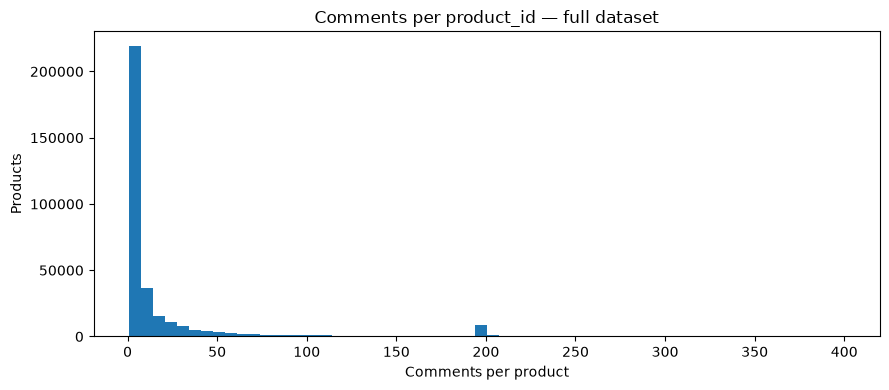

In [43]:
# Disk-backed exact frequency tables avoid storing millions of unique text keys in RAM.
tmpdb=tempfile.NamedTemporaryFile(suffix=".sqlite",delete=False); dbpath=tmpdb.name; tmpdb.close()
con=sqlite3.connect(dbpath)
con.execute("CREATE TABLE ids (v TEXT PRIMARY KEY,n INTEGER NOT NULL)")
con.execute("CREATE TABLE bodies (v TEXT PRIMARY KEY,n INTEGER NOT NULL)")
con.execute("CREATE TABLE body_labels (body TEXT,label TEXT,n INTEGER NOT NULL,PRIMARY KEY(body,label))")
con.execute("CREATE TABLE product_freq (v TEXT PRIMARY KEY,n INTEGER NOT NULL)")
for chunk in pd.read_csv(COMMENTS_PATH,chunksize=CHUNK_SIZE,dtype={"id":"string","product_id":"string","recommendation_status":"string"},low_memory=False,usecols=["id","body","product_id","recommendation_status"]):
    for col,table in [("id","ids"),("product_id","product_freq")]:
        vc=chunk[col].dropna().astype(str).value_counts()
        con.executemany(f"INSERT INTO {table}(v,n) VALUES (?,?) ON CONFLICT(v) DO UPDATE SET n=n+excluded.n",[(k,int(v)) for k,v in vc.items()])
    body=chunk["body"].fillna("").astype(str); label=chunk["recommendation_status"].fillna("<MISSING>").astype(str).str.strip().replace("","<BLANK>")
    valid=body.str.strip().ne("")
    vc=body[valid].value_counts()
    con.executemany("INSERT INTO bodies(v,n) VALUES (?,?) ON CONFLICT(v) DO UPDATE SET n=n+excluded.n",[(k,int(v)) for k,v in vc.items()])
    pairs=pd.DataFrame({"body":body[valid],"label":label[valid]}).value_counts()
    con.executemany("INSERT INTO body_labels(body,label,n) VALUES (?,?,?) ON CONFLICT(body,label) DO UPDATE SET n=n+excluded.n",[(b,l,int(v)) for (b,l),v in pairs.items()])
con.commit()

pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)


print("ID frequency summary (distinct repeated IDs / rows within repeated IDs / extra duplicate occurrences):")
display(pd.read_sql_query("SELECT COUNT(*) unique_ids, SUM(n>1) distinct_repeated_ids, SUM(CASE WHEN n>1 THEN n ELSE 0 END) rows_in_repeated_ids, SUM(n-1) extra_duplicate_occurrences FROM ids",con))
print("Repeated non-empty body summary:")
display(pd.read_sql_query("SELECT COUNT(*) unique_bodies, SUM(n>1) distinct_repeated_bodies, SUM(CASE WHEN n>1 THEN n ELSE 0 END) rows_in_repeated_bodies, SUM(n-1) extra_repetitions, MAX(n) max_repetitions FROM bodies",con))
print("Identical bodies that have multiple raw label values:",con.execute("SELECT COUNT(*) FROM (SELECT body FROM body_labels GROUP BY body HAVING COUNT(DISTINCT label)>1)").fetchone()[0])
print("Top repeated bodies:"); display(pd.read_sql_query("SELECT v AS body,n FROM bodies WHERE n>1 ORDER BY n DESC LIMIT 20",con))
print("Top identical-text label conflicts:")
display(pd.read_sql_query("SELECT body,GROUP_CONCAT(label || ': ' || n,' | ') label_counts FROM body_labels GROUP BY body HAVING COUNT(DISTINCT label)>1 ORDER BY SUM(n) DESC LIMIT 20",con))
product_freq=np.array([r[0] for r in con.execute("SELECT n FROM product_freq")],dtype=np.int64)
print("Comments per product_id distribution:"); display(pd.Series(product_freq,name="comments_per_product").describe(percentiles=[.5,.75,.9,.95,.99]).to_frame())
for k in [1,10,100,1000]:
    top=int(np.sort(product_freq)[-min(k,len(product_freq)):].sum())
    print(f"Top {k} products share: {100*top/max(int(product_freq.sum()),1):.2f}%")
plt.figure(figsize=(9,4)); plt.hist(product_freq,bins=60); plt.title("Comments per product_id — full dataset"); plt.xlabel("Comments per product"); plt.ylabel("Products"); plt.tight_layout(); plt.show()

### A5 interpretation: duplicate-count definitions

- **Distinct repeated IDs** counts ID values occurring at least twice.
- **Rows in repeated IDs** counts every row with one of those IDs, including the first occurrence.
- **Extra duplicate occurrences** counts only appearances after the first; if no IDs are missing, this equals total rows minus unique IDs.
- Identical text with conflicting labels should be audited, not silently relabeled. Do not automatically drop duplicates until the deduplication policy is explicitly chosen.

Product concentration motivates a product-grouped train/validation/test split: all rows for a `product_id` should stay in one partition to reduce leakage.

### A6. Optional vocabulary analysis (bounded sample)

In [42]:
# Optional, explicitly bounded sample. No stopword list is applied automatically.
SAMPLE_PER_CHUNK=200
sample_chunks=[]
for chunk in pd.read_csv(COMMENTS_PATH,chunksize=CHUNK_SIZE,usecols=["body","recommendation_status"],dtype={"recommendation_status":"string"},low_memory=False):
    sample_chunks.append(chunk.sample(n=min(SAMPLE_PER_CHUNK,len(chunk)),random_state=RANDOM_SEED))
    if len(sample_chunks)*SAMPLE_PER_CHUNK>=100_000: break
sample_text=pd.concat(sample_chunks,ignore_index=True)
print(f"Vocabulary sample rows: {len(sample_text):,}; up to {SAMPLE_PER_CHUNK} rows per chunk; random_state={RANDOM_SEED}.")
from collections import Counter
word_counter=Counter()
for text in sample_text["body"].dropna().astype(str):
    word_counter.update(text.split())
display(pd.DataFrame(word_counter.most_common(30),columns=["token","sample_frequency"]))


Vocabulary sample rows: 12,400; up to 200 rows per chunk; random_state=42.


,token,sample_frequency
0,و,5490
1,خیلی,2714
2,بود,2556
3,خوب,2238
4,به,2170
5,از,1873
6,خوبه,1806
7,که,1786
8,عالی,1547
9,من,1503


### A7. Conclusions linked to modeling decisions

## Key Conclusions from Data Quality Analysis

1. **Class imbalance:** Recommendation labels may be imbalanced. Model evaluation should include Macro F1, per-class Precision, Recall and F1-score, and Balanced Accuracy rather than relying on accuracy alone.

2. **Missing recommendation labels:** Reviews with missing recommendation labels should not be treated as supervised targets. They may be used only through a clearly documented unlabeled-learning or pseudo-labeling approach.

3. **Target leakage prevention:** The `rate` column is used only to derive `rating_band` using fixed thresholds (`low`, `medium`, and `high`). Neither `rate` nor target-related columns should be used as model input features.

4. **Text sequence length:** Global text-length percentiles should guide the selection of `max_length`. Tokenizer truncation rates should be measured for candidate lengths such as 128 and 256 before choosing the final value.

5. **Duplicate reviews and conflicting labels:** Repeated IDs and identical review bodies with conflicting recommendation labels require a documented audit and deduplication policy before training.

6. **Product-level data leakage:** Differences in review counts across products motivate product-grouped train/test splitting to reduce the risk of product-level data leakage.

7. **Persian text preprocessing:** Persian reviews may contain colloquial expressions, spelling variations, and line breaks. Raw text should be preserved during auditing, and normalization should be evaluated experimentally rather than assumed to improve performance.

## Plot/data-basis disclosure and final policy

- Missing-value tables, target counts, rating-band counts, rate statistics, text-length statistics, duplicate summaries, and product concentration are computed from the full CSV files.
- Vocabulary examples are a bounded sample: up to 200 rows per chunk, fixed seed 2026, and only the first 100,000 sampled rows at most.
- All rating-band thresholds remain fixed to the project definition: low `[0, 2.5)`, medium `[2.5, 4.0)`, high `[4.0, 5.0]`.
- Model input is **only `body`**. Do not include title, rate, recommendation label, rating_band, product/seller identifiers, timestamps, likes/dislikes, advantages/disadvantages, or other metadata as features.
- Missing recommendation labels are excluded from supervised recommendation loss. Invalid rates are excluded from Task B target rows. Do not silently coerce labels, drop duplicates, or alter thresholds.
